In [1]:
rm(list = ls())
options(stringsAsFactors = FALSE)
getwd()

[1] "/Users/luye/Library/Mobile Documents/com~apple~CloudDocs/Projects/Ongoing/202504ZL"

In [5]:
library(readxl)
library(dplyr)
library(tidyverse)

## **Data Preparation**

In [5]:
sample_cluster <- readxl::read_excel("./1-Clustering/data/sample_info_with_clusters.xlsx")
dim(sample_cluster)
head(sample_cluster)

[1] 586  38

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,⋯,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,⋯,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,⋯,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,⋯,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,⋯,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,⋯,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,⋯,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


In [5]:
load(file =  "./1-Clustering/data/combined_expr_after_correction.rds")
rna_zscore <- t(apply(corrected_expr_limma, 1, scale))
# 将列名重新赋给Z-score矩阵
colnames(rna_zscore) <- colnames(corrected_expr_limma)
# 检查一下结果
# 检查第一行（第一个基因）的均值是否接近0，标准差是否为1
mean(rna_zscore[1, ]) # 应该非常接近0
sd(rna_zscore[1, ])   # 应该为1
dim(rna_zscore)
head(rna_zscore)

[1] 5.895928e-16

[1] 1

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,⋯,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,-0.5924227,-0.5214293,0.6912298,1.6494750,-0.4016346,-0.1358434,-1.5056946,-1.0877622,-0.04626317,0.94901562,⋯,-0.3999557,-0.3659370,-0.2870030,0.7640829,0.1576496,1.4756046,0.4895827,0.0821011,-0.1641921,-2.1268778
ALB,0.7238102,1.0856033,0.3218541,-1.2896272,-0.8748798,-1.6796594,0.9125646,0.8510974,0.09237367,0.07437279,⋯,0.3886328,0.7706393,0.2855643,0.8672751,-2.3667248,-0.4294144,-0.7634648,-2.9817793,0.8949932,-0.7243114
FTL,-0.8329614,1.6212772,0.3286764,-0.3856351,0.7915444,0.7851010,2.6738949,0.9831767,-0.36604774,-0.37726277,⋯,0.3780312,-1.8061885,-0.9511934,-1.0899304,0.9652420,1.0078499,2.1337123,0.2415321,-0.7619028,0.0237256
S100A6,0.2480230,-2.7426120,1.0220191,0.6760608,0.7197471,0.1309850,-1.3564256,0.6183383,0.41309113,0.48701109,⋯,0.4404145,0.4917821,-0.7761767,-1.2739297,1.5290006,1.2410202,0.4189567,-1.0458586,-0.6197456,-0.9619945
RPS18,0.1415996,0.2373886,0.5891131,0.3770575,-0.5180793,-1.1601179,-0.9705005,-0.2547407,1.90347678,0.14899821,⋯,0.8302505,1.4473805,-0.4540711,0.7360857,-0.5444029,-0.4234391,-0.1302038,1.4534270,0.7971992,-0.4053811
TMSB4X,-0.3705988,-0.6128989,0.4502915,0.9239164,0.4382566,0.4233451,-0.1815443,0.5609974,-0.05248839,1.07448189,⋯,-0.5821542,-0.4035661,-0.6467762,0.4320060,0.9387928,1.2437207,-0.4235398,1.7936998,-0.0814156,-1.9750583


In [6]:
# 1. 定义主要分型
major_subtypes <- c("C1", "C2", "C3")

# 2. 筛选出只包含主要分型的样本信息
rna_sample_info_major <- sample_cluster %>%
  filter(Ensemble %in% major_subtypes)

# **非常重要**：确保factor的levels也被更新，去掉不再存在的中间态level
rna_sample_info_major$Ensemble <- factor(rna_sample_info_major$Ensemble)

# 3. 根据筛选后的样本信息，对Z-score矩阵进行子集化
# 确保样本顺序和信息表一致
samples_to_keep <- rna_sample_info_major$Sample
rna_zscore_major <- rna_zscore[, samples_to_keep]

In [7]:
load(file = "./0-Data/0-Data-rnaseq-microarray1.Rdata")
load(file = "./0-Data/0-Data-rnaseq-microarray2.Rdata")
ls()

[1] "corrected_expr_limma"  "dat_2012Andersen"      "dat_2013Sia"          
 [4] "dat_2017Jusakual1"     "dat_2017Jusakual2"     "log2dat_2012Andersen" 
 [7] "log2dat_2013Sia"       "log2dat_2017Jusakual1" "log2dat_2017Jusakual2"
[10] "log2dat_2020Job"       "log2dat_TIGER"         "major_subtypes"       
[13] "rna_sample_info_major" "rna_zscore"            "rna_zscore_major"     
[16] "sample_cluster"        "sample_info"           "samples_to_keep"

In [8]:
# 1. 找到共同基因
common_genes <- intersect(rownames(log2dat_2017Jusakual1), rownames(log2dat_2017Jusakual2))
# 2. 提取共同基因的数据子集
sub1 <- log2dat_2017Jusakual1[common_genes, , drop = FALSE]
sub2 <- log2dat_2017Jusakual2[common_genes, , drop = FALSE]
# 3. 合并两个矩阵（按列合并，行名为基因，列名为样本）
log2dat_2017Jusakual <- cbind(sub1, sub2)
# 4. 查看合并结果的维度
dim(log2dat_2017Jusakual)

[1] 34631    83

In [10]:
list_log_norm <- list(
    '2012Andersen' = log2dat_2012Andersen, 
    '2013Sia' = log2dat_2013Sia,
    '2017Jusakual' = log2dat_2017Jusakual,
    '2020Job' = log2dat_2020Job,
    'TIGER' = log2dat_TIGER
    )

# 创建一个空的list来存储Z-score标准化后的结果
list_validation_zscore <- list()

# 循环遍历每一个Illumina数据集
for (dataset_name in names(list_log_norm)) {
  
  cat("Processing Z-score for:", dataset_name, "\n")
  # 提取当前数据集
  current_matrix <- list_log_norm[[dataset_name]]
  # 对当前数据集进行Z-score标准化
  zscore_matrix <- t(apply(current_matrix, 1, scale))
  colnames(zscore_matrix) <- colnames(current_matrix)
  # 将结果存入新的list
  list_validation_zscore[[dataset_name]] <- zscore_matrix
}

str(list_validation_zscore)

Processing Z-score for: 2012Andersen 
Processing Z-score for: 2013Sia 
Processing Z-score for: 2017Jusakual 
Processing Z-score for: 2020Job 
Processing Z-score for: TIGER 
List of 5
 $ 2012Andersen: num [1:18190, 1:104] 0.9363 0.5296 0.2661 0.5057 -0.0162 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:18190] "EEF1A1" "TMSB4X" "ACTB" "FTL" ...
  .. ..$ : chr [1:104] "GSM653074" "GSM653075" "GSM653076" "GSM653077" ...
 $ 2013Sia     : num [1:18402, 1:149] -1.3006 0.6245 1.4789 -2.6771 0.0878 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:18402] "ACTN1" "CIB1" "CXCR4" "F2R" ...
  .. ..$ : chr [1:149] "CCBCN001" "CCBCN002" "CCBCN003" "CCBCN004" ...
 $ 2017Jusakual: num [1:34631, 1:83] 0.812 1.245 1.721 1.004 1.228 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:34631] "EEF1A1" "TPT1" "RPL41" "TMSB4X" ...
  .. ..$ : chr [1:83] "CCA_SG_20" "CCA_TH_9" "CCA_TH_17" "CCA_TH_18" ...
 $ 2020Job     : num [1:21641, 1:78] -1.061 -0.122 1.076 0.817 1.595 ...
  ..- att

In [11]:
sample_info <- readxl::read_excel("./sample_information.xlsx")
dim(sample_info)
head(sample_info)

[1] 1092   34

SampleID,Study,Platform,Sex,Age,Country,Race,iCCA classification,Subclass,Subclass-add,⋯,"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,RNA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
111,2022Dong,RNAseq (Illumina),Male,49,China,Asian,w/o,NA,IG2,⋯,8.4,36,5147,2.5,25.2,18,80,YES,NO,NA
113,2022Dong,RNAseq (Illumina),Male,59,China,Asian,w/o,NA,IG2,⋯,9.2,38,1.8,2.8,35,18,40,YES,NO,NA
115,2022Dong,RNAseq (Illumina),Male,74,China,Asian,w/o,S4,IG3,⋯,7.9,39,42.7,2.0,8.1999999999999993,11,29,YES,YES,NA
117,2022Dong,RNAseq (Illumina),Female,64,China,Asian,w/o,S3,IG3,⋯,14.1,47,2.8,1.0,7.9,17,27,YES,YES,NA
121,2022Dong,RNAseq (Illumina),Female,71,China,Asian,w/o,S4,IG3,⋯,8.6,42,215.1,1.4,24.9,10,23,YES,YES,NA
123,2022Dong,RNAseq (Illumina),Male,55,China,Asian,w/o,S3,IG2,⋯,17.8,44,2.1,0.8,30.4,89,384,YES,YES,NA


In [12]:
save(
    rna_zscore,rna_zscore_major,rna_sample_info_major, 
    list_validation_zscore, sample_info, 
    file = "./4-Validation/input_validation_data.rds")

## **Classification Validation**

In [14]:
## 第1步：准备工作 - 加载包和创建模拟数据
# --- 加载所需R包 ---
# 如果没有安装，请先运行 install.packages(c("randomForest", "glmnet", "caret", "dplyr", "pheatmap"))
library(randomForest) # 用于随机森林
library(limma)
library(glmnet)       # 用于LASSO回归
library(caret)        # 用于数据划分和模型训练流程
library(dplyr)        # 用于数据整理
library(pheatmap)     # 用于绘制热图
library(VennDiagram) # 用于绘制韦恩图
set.seed(42)

In [15]:
load(file = "./4-Validation/input_validation_data.rds")
ls()

[1] "common_genes"           "corrected_expr_limma"   "current_matrix"        
 [4] "dat_2012Andersen"       "dat_2013Sia"            "dat_2017Jusakual1"     
 [7] "dat_2017Jusakual2"      "dataset_name"           "list_log_norm"         
[10] "list_validation_zscore" "log2dat_2012Andersen"   "log2dat_2013Sia"       
[13] "log2dat_2017Jusakual"   "log2dat_2017Jusakual1"  "log2dat_2017Jusakual2" 
[16] "log2dat_2020Job"        "log2dat_TIGER"          "major_subtypes"        
[19] "rna_sample_info_major"  "rna_zscore"             "rna_zscore_major"      
[22] "sample_cluster"         "sample_info"            "samples_to_keep"       
[25] "sub1"                   "sub2"                   "zscore_matrix"

### **特征基因selection**

In [16]:
# ①基于统计显著性 (limma)
cat("\n--- 策略一：使用 limma 寻找差异表达基因 ---\n")
# 创建设计矩阵
rna_sample_info_major$Ensemble <- factor(rna_sample_info_major$Ensemble)
design <- model.matrix(~ 0 + Ensemble, data = rna_sample_info_major)
colnames(design) <- levels(rna_sample_info_major$Ensemble)
# 拟合线性模型
fit <- lmFit(rna_zscore_major, design)

# 创建对比矩阵，进行两两比较
contrast_matrix <- makeContrasts(
  C1_vs_C2 = C1 - C2,
  C1_vs_C3 = C1 - C3,
  C2_vs_C3 = C2 - C3,
  levels = colnames(design)
)
fit2 <- contrasts.fit(fit, contrast_matrix)
fit2 <- eBayes(fit2)

# 1.2 提取每个比较组的Top差异基因
top_n_genes <- 30 # 每个比较组上下调各选30个，可根据需求调整
signature_genes <- character()

for (coef_name in colnames(contrast_matrix)) {
  top_genes <- topTable(fit2, coef = coef_name, number = Inf, sort.by = "logFC")
  # 筛选 p.value < 0.05
  top_genes <- top_genes[top_genes$adj.P.Val < 0.05, ]
  
  # 分别提取上调和下调的基因
  up_genes <- head(rownames(top_genes[top_genes$logFC > 0, ]), top_n_genes)
  down_genes <- head(rownames(top_genes[top_genes$logFC < 0, ]), top_n_genes)
  
  signature_genes <- c(signature_genes, up_genes, down_genes)
}
# 去除重复基因
signature_genes_limma <- unique(signature_genes)
cat("limma筛选出", length(signature_genes_limma), "个特征基因。\n")


--- 策略一：使用 limma 寻找差异表达基因 ---
limma筛选出 163 个特征基因。


In [17]:
cat("\n--- 策略二：基于Random Forest内置重要性筛选 ---\n")

# 准备训练数据 (使用所有基因)
rf_train_data <- as.data.frame(t(rna_zscore_major))
rf_train_data$Ensemble <- rna_sample_info_major$Ensemble

colnames(rf_train_data) <- make.names(colnames(rf_train_data))

# 训练一个初步的RF模型来评估基因重要性
# 注意：这一步可能会比较耗时
rf_initial_model <- randomForest(
  Ensemble ~ .,
  data = rf_train_data,
  ntree = 500,
  importance = TRUE
)

# 提取特征重要性
feature_importance <- importance(rf_initial_model, type = 1) # type=1 is MeanDecreaseAccuracy

# 按重要性排序并选择Top N基因
# 这里的N可以参考limma结果的数量，比如选择Top 200
top_n_rf <- 200
signature_genes_rf <- names(sort(feature_importance[, 1], decreasing = TRUE))[1:top_n_rf]

cat("Random Forest筛选出", length(signature_genes_rf), "个特征基因。\n")


--- 策略二：基于Random Forest内置重要性筛选 ---
Random Forest筛选出 200 个特征基因。


In [18]:
#③基于正则化惩罚 (LASSO)
cat("\n--- 策略三：基于LASSO回归筛选 ---\n")

# 准备LASSO的输入数据
x_lasso <- t(rna_zscore_major)
y_lasso <- rna_sample_info_major$Ensemble

# 使用交叉验证来寻找最佳的lambda值
# alpha=1 表示使用LASSO回归
cv_lasso <- cv.glmnet(
  x = x_lasso,
  y = y_lasso,
  family = "multinomial",
  alpha = 1,
  type.multinomial = "grouped"
)

# 提取在最佳lambda (lambda.min) 下系数不为0的基因
lasso_coefs <- coef(cv_lasso, s = "lambda.min")

# lasso_coefs是一个包含每个类别的列表
# 我们需要提取所有类别中系数不为0的基因
selected_genes_list <- lapply(lasso_coefs, function(coef_matrix) {
  non_zero_indices <- which(coef_matrix != 0)
  # 排除截距项 (Intercept)
  if (length(non_zero_indices) > 1) {
    rownames(coef_matrix)[non_zero_indices[-1]]
  } else {
    NULL
  }
})

signature_genes_lasso <- unique(unlist(selected_genes_list))

cat("LASSO回归筛选出", length(signature_genes_lasso), "个特征基因。\n")


--- 策略三：基于LASSO回归筛选 ---
LASSO回归筛选出 87 个特征基因。


In [19]:
cat("\n--- 步骤四：寻找交集并评估 ---\n")
# --- 请确保您已经将limma的结果存入了 signature_genes_limma ---
# 假设: signature_genes_limma <- 您的163个基因向量

# 计算两两交集
intersect_limma_rf <- intersect(signature_genes_limma, signature_genes_rf)
intersect_limma_lasso <- intersect(signature_genes_limma, signature_genes_lasso)
intersect_rf_lasso <- intersect(signature_genes_rf, signature_genes_lasso)

# 计算三者交集
intersect_all_three <- intersect(intersect_limma_rf, signature_genes_lasso)

cat("Limma & RF 交集基因数:", length(intersect_limma_rf), "\n")
cat("Limma & LASSO 交集基因数:", length(intersect_limma_lasso), "\n")
cat("RF & LASSO 交集基因数:", length(intersect_rf_lasso), "\n")
cat("三种方法共同的交集基因数:", length(intersect_all_three), "\n")


--- 步骤四：寻找交集并评估 ---
Limma & RF 交集基因数: 104 


Limma & LASSO 交集基因数: 38 
RF & LASSO 交集基因数: 43 
三种方法共同的交集基因数: 31 


In [20]:
# 获取所有在至少两种方法中出现的基因
genes_in_at_least_two <- unique(c(intersect_limma_rf, intersect_limma_lasso, intersect_rf_lasso))
cat("在至少两种方法中被选中的基因数:", length(genes_in_at_least_two), "\n")

在至少两种方法中被选中的基因数: 123 


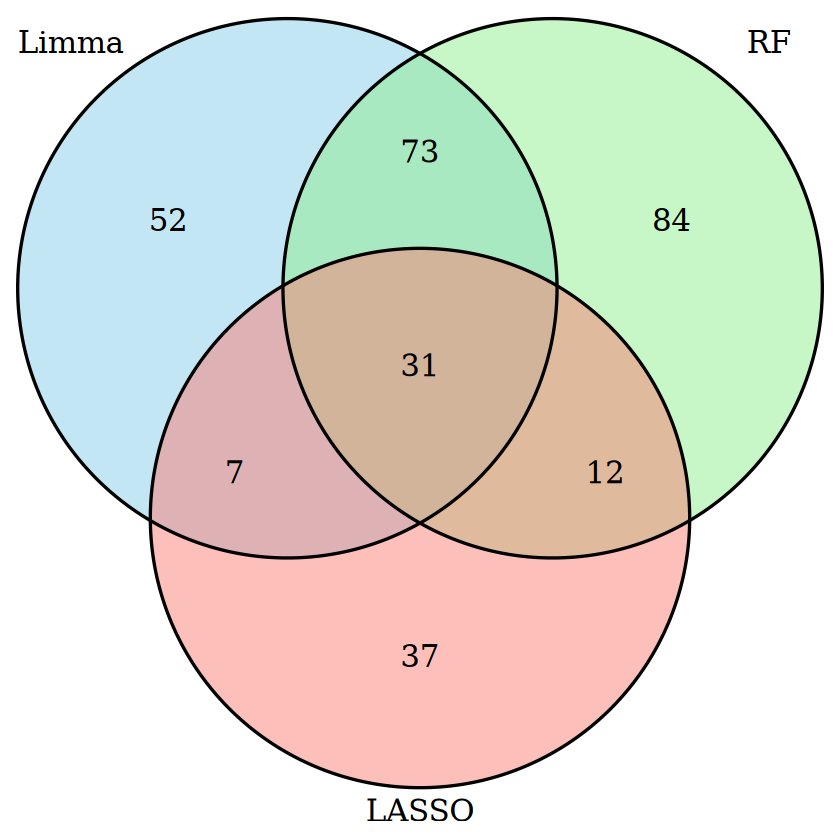

In [21]:
# 可视化交集 - 韦恩图
grid.newpage() # 如果需要，清空画板
venn_plot <- venn.diagram(
   x = list(
     Limma = signature_genes_limma,
     RF = signature_genes_rf,
     LASSO = signature_genes_lasso
   ),
   filename = NULL, # 设置为NULL直接在R中显示
   fill = c("skyblue", "lightgreen", "salmon"),
   alpha = 0.5,
   cex = 1.5,
   cat.cex = 1.5
)
grid.draw(venn_plot)

In [22]:
save(signature_genes_limma,signature_genes_rf,signature_genes_lasso,
     intersect_all_three,genes_in_at_least_two,
     file = "./4-Validation/selected_signature_genes.rds")

In [23]:
intersect_all_three

[1] "SLC38A4"  "CPN2"     "CPS1"     "PLG"      "TF"       "C2"      
 [7] "APOA5"    "C8A"      "BHMT"     "B4GALNT4" "ITIH5"    "AFM"     
[13] "ACSM2A"   "CDH3"     "FHL2"     "GPRC5A"   "NHS"      "VILL"    
[19] "DCDC2"    "ONECUT1"  "PROX1"    "DEFB1"    "HOGA1"    "SHC2"    
[25] "SNAP25"   "PPARGC1A" "KCNN4"    "BCL2L15"  "SLC44A4"  "CREB3L1" 
[31] "CTSE"

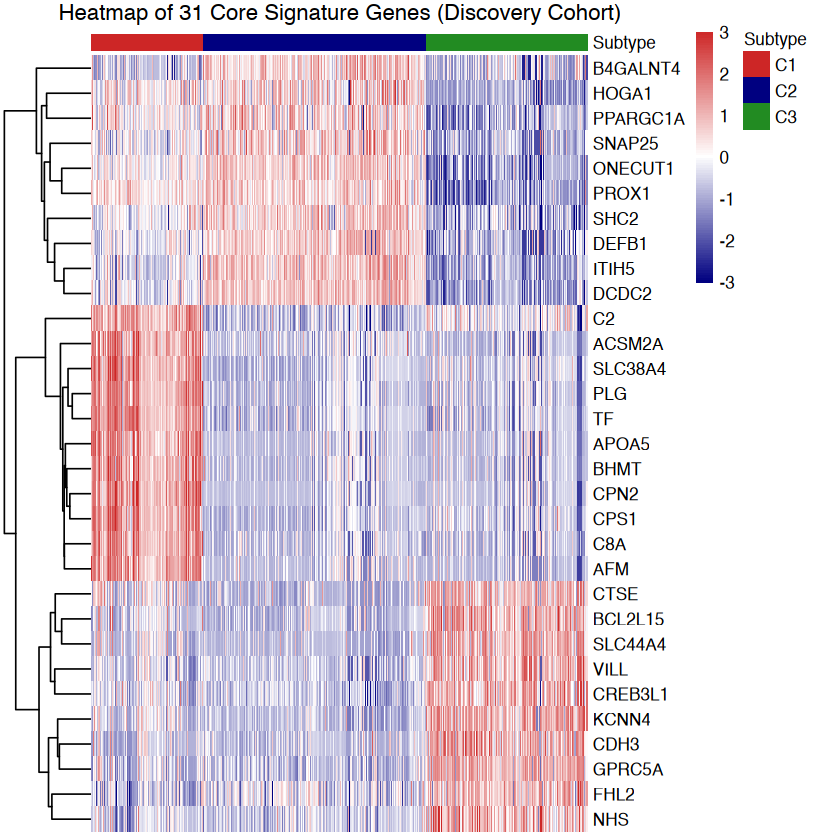

In [24]:
# 1.1 提取31个核心基因的表达矩阵
# 确保 intersect_all_three 中的基因存在于 rna_zscore_major 的行名中
expr_heatmap <- rna_zscore_major[intersect_all_three, ]
# 1.2 准备样本注释信息 (Annotation)
sample_anno <- data.frame(
  Subtype = rna_sample_info_major$Ensemble
)
rownames(sample_anno) <- rna_sample_info_major$Sample
# 1.3 **优化点：** 按照亚型对样本进行排序，以获得更清晰的可视化效果
# 首先获取排序后的样本顺序
ordered_samples <- rna_sample_info_major %>%
  arrange(Ensemble) %>%
  pull(Sample)
# 使用这个顺序来排列表达矩阵的列和注释信息的行
expr_heatmap_ordered <- expr_heatmap[, ordered_samples]
sample_anno_ordered <- sample_anno[ordered_samples, , drop = FALSE]

# --- 2. 绘制热图 ---
# 2.1 定义颜色和断点，确保颜色映射的中心在0
# 因为是Z-score，数据范围通常在-2.5到2.5之间，我们可以设置得更宽一点以防万一
breaksList <- seq(-3, 3, by = 0.06)
# 2.2 (可选但推荐) 为注释的亚型定义颜色
ann_colors <- list(
  Subtype = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen")
)
# 2.3 绘制最终的热图
pheatmap(
  expr_heatmap_ordered,
  annotation_col = sample_anno_ordered,
  annotation_colors = ann_colors, # 应用自定义颜色
  # scale = "row", # 已删除，因为输入数据已是Z-score
  cluster_cols = FALSE, # **重要**：因为我们已经手动排序，所以这里设为FALSE
  cluster_rows = TRUE,  # 对基因进行聚类，寻找协同表达的模块
  show_colnames = FALSE, # 样本量大，不显示样本名
  main = "Heatmap of 31 Core Signature Genes (Discovery Cohort)",
  color = colorRampPalette(c("navy", "white", "firebrick3"))(length(breaksList)),
  breaks = breaksList,
  border_color = NA # 去掉格子边框，更美观
)

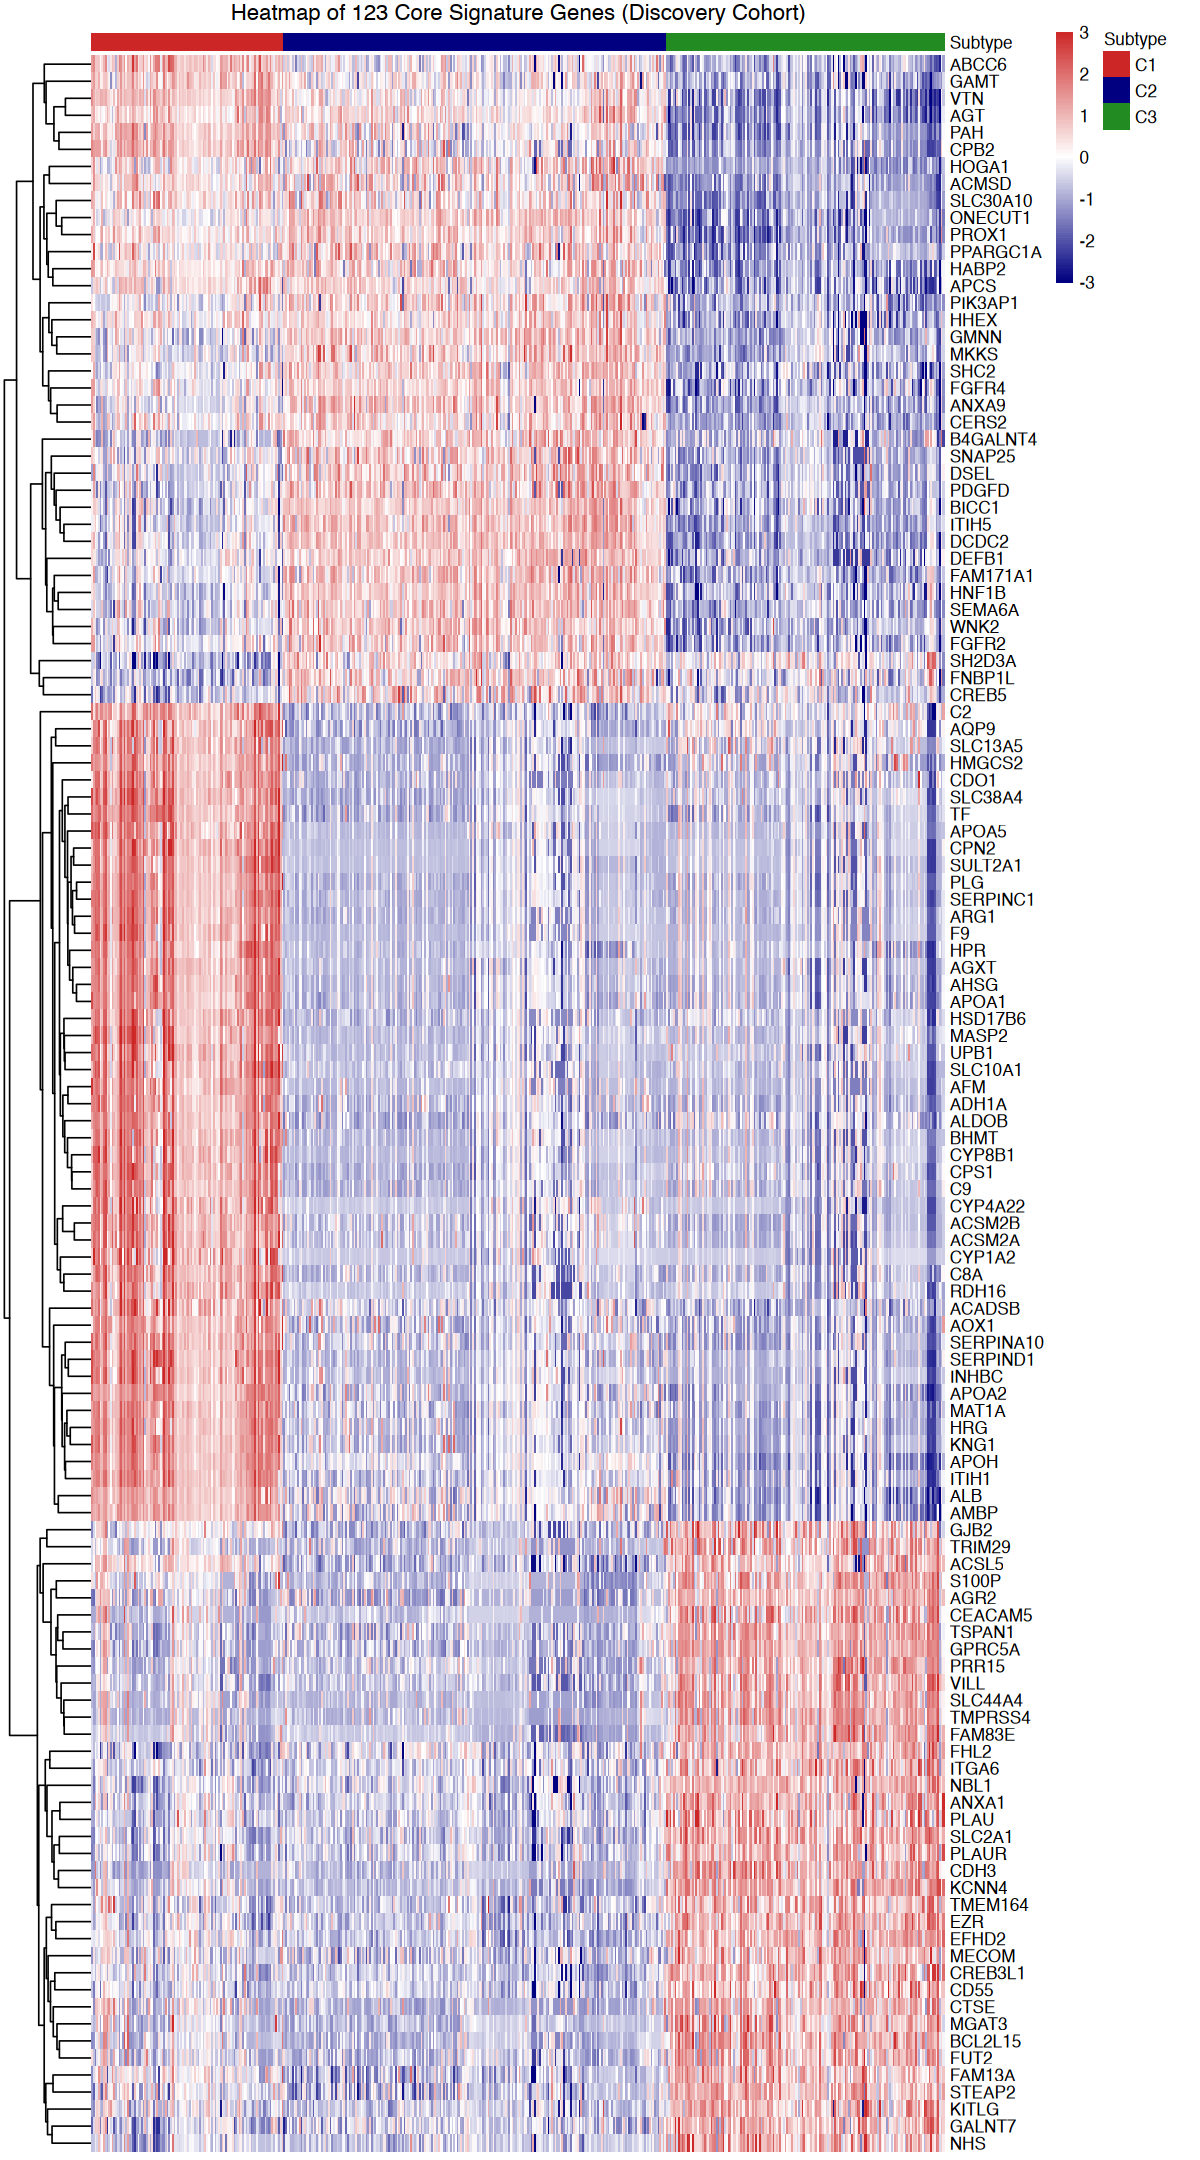

In [25]:
# 1.1 提取31个核心基因的表达矩阵
# 确保 intersect_all_three 中的基因存在于 rna_zscore_major 的行名中
expr_heatmap <- rna_zscore_major[genes_in_at_least_two, ]
# 1.2 准备样本注释信息 (Annotation)
sample_anno <- data.frame(
  Subtype = rna_sample_info_major$Ensemble
)
rownames(sample_anno) <- rna_sample_info_major$Sample
# 1.3 **优化点：** 按照亚型对样本进行排序，以获得更清晰的可视化效果
# 首先获取排序后的样本顺序
ordered_samples <- rna_sample_info_major %>%
  arrange(Ensemble) %>%
  pull(Sample)
# 使用这个顺序来排列表达矩阵的列和注释信息的行
expr_heatmap_ordered <- expr_heatmap[, ordered_samples]
sample_anno_ordered <- sample_anno[ordered_samples, , drop = FALSE]

# --- 2. 绘制热图 ---
# 2.1 定义颜色和断点，确保颜色映射的中心在0
# 因为是Z-score，数据范围通常在-2.5到2.5之间，我们可以设置得更宽一点以防万一
breaksList <- seq(-3, 3, by = 0.06)
# 2.2 (可选但推荐) 为注释的亚型定义颜色
ann_colors <- list(
  Subtype = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen")
)
# 2.3 绘制最终的热图
options(repr.plot.width=10, repr.plot.height=18)
pheatmap(
  expr_heatmap_ordered,
  annotation_col = sample_anno_ordered,
  annotation_colors = ann_colors, # 应用自定义颜色
  # scale = "row", # 已删除，因为输入数据已是Z-score
  cluster_cols = FALSE, # **重要**：因为我们已经手动排序，所以这里设为FALSE
  cluster_rows = TRUE,  # 对基因进行聚类，寻找协同表达的模块
  show_colnames = FALSE, # 样本量大，不显示样本名
  main = "Heatmap of 123 Core Signature Genes (Discovery Cohort)",
  color = colorRampPalette(c("navy", "white", "firebrick3"))(length(breaksList)),
  breaks = breaksList,
  border_color = NA # 去掉格子边框，更美观
)

In [8]:
# 加载所有需要的包
library(umap)
library(ggplot2)
library(dplyr)
library(tidyr) # tidyr::pivot_longer 是比 reshape2::melt 更现代化的选择

# --- 请在这里二选一 ---
# 选项A: 使用31个核心基因
#signature_to_use <- intersect_all_three 
#plot_title_prefix <- "31 Core Signature Genes"

# 选项B: 使用123个共识基因
signature_to_use <- genes_in_at_least_two 
plot_title_prefix <- "123 Consensus Signature Genes"

# 准备用于作图的表达矩阵和样本信息
# 确保变量名与之前步骤一致
expr_for_plotting <- rna_zscore_major[signature_to_use, ]
sample_info_for_plotting <- rna_sample_info_major

# 检查样本顺序是否一致 (最佳实践)
stopifnot(all(colnames(expr_for_plotting) == sample_info_for_plotting$Sample))

# 定义颜色，与热图保持一致
subtype_colors <- c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen")


--- 正在生成UMAP图 ---


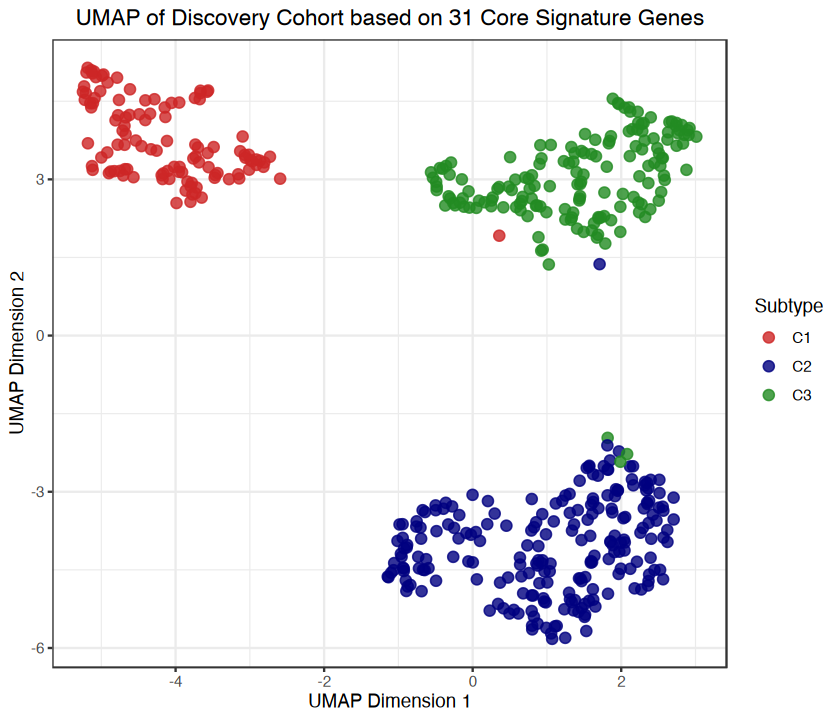

In [7]:
cat("\n--- 正在生成UMAP图 ---\n")

# 1. 运行UMAP算法
# umap需要行为样本，列为基因的矩阵，所以需要转置
umap_result <- umap(t(expr_for_plotting))

# 2. 创建用于ggplot作图的数据框
df_umap <- data.frame(
  UMAP1 = umap_result$layout[, 1],
  UMAP2 = umap_result$layout[, 2],
  Subtype = sample_info_for_plotting$Ensemble
)
options(repr.plot.width=7, repr.plot.height=6)
# 3. 使用ggplot2绘制UMAP图
ggplot(df_umap, aes(x = UMAP1, y = UMAP2, color = Subtype)) +
  geom_point(size = 2.5, alpha = 0.8) +
  scale_color_manual(values = subtype_colors) + # 使用统一的颜色
  labs(
    title = paste("UMAP of Discovery Cohort based on", plot_title_prefix),
    x = "UMAP Dimension 1",
    y = "UMAP Dimension 2",
    color = "Subtype"
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    legend.position = "right"
  )

# 如果您想直接保存图片
# ggsave(paste0("UMAP_", gsub(" ", "_", plot_title_prefix), ".png"), width = 7, height = 6)


--- 正在生成UMAP图 ---


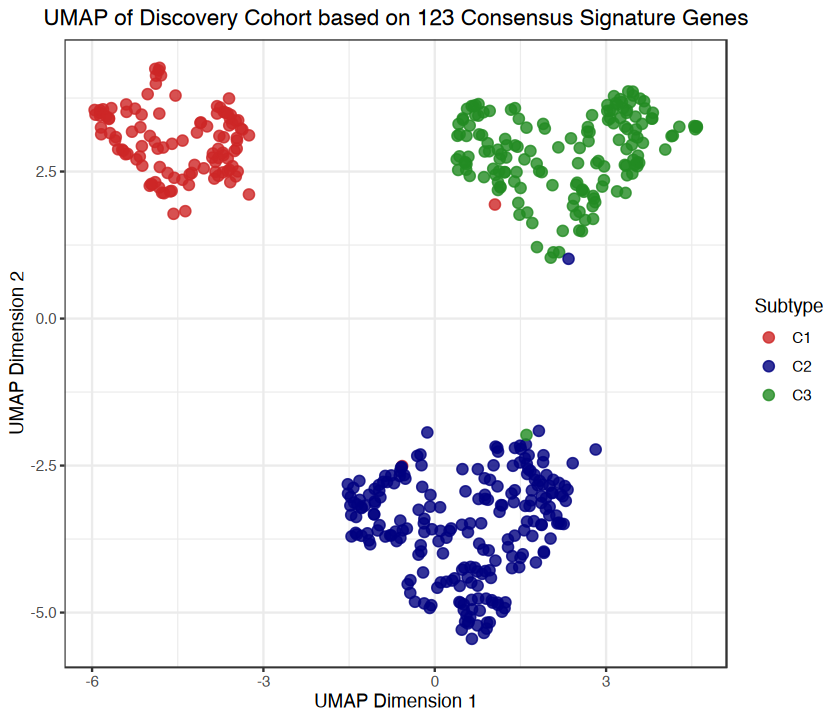

In [9]:
cat("\n--- 正在生成UMAP图 ---\n")

# 1. 运行UMAP算法
# umap需要行为样本，列为基因的矩阵，所以需要转置
umap_result <- umap(t(expr_for_plotting))

# 2. 创建用于ggplot作图的数据框
df_umap <- data.frame(
  UMAP1 = umap_result$layout[, 1],
  UMAP2 = umap_result$layout[, 2],
  Subtype = sample_info_for_plotting$Ensemble
)
options(repr.plot.width=7, repr.plot.height=6)
# 3. 使用ggplot2绘制UMAP图
ggplot(df_umap, aes(x = UMAP1, y = UMAP2, color = Subtype)) +
  geom_point(size = 2.5, alpha = 0.8) +
  scale_color_manual(values = subtype_colors) + # 使用统一的颜色
  labs(
    title = paste("UMAP of Discovery Cohort based on", plot_title_prefix),
    x = "UMAP Dimension 1",
    y = "UMAP Dimension 2",
    color = "Subtype"
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    legend.position = "right"
  )

# 如果您想直接保存图片
# ggsave(paste0("UMAP_", gsub(" ", "_", plot_title_prefix), ".png"), width = 7, height = 6)


--- 正在生成小提琴图 ---


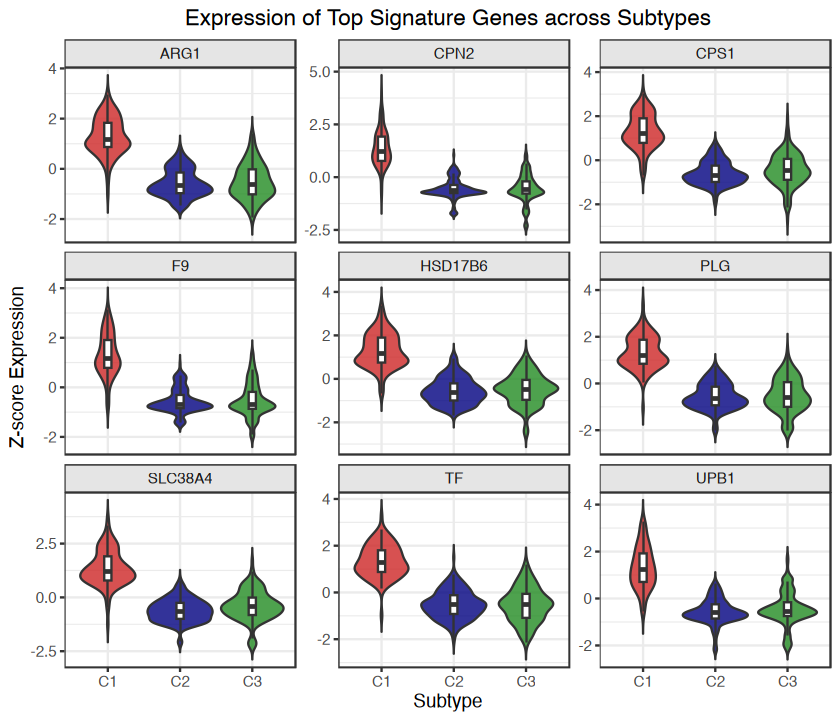

In [29]:
cat("\n--- 正在生成小提琴图 ---\n")

# 1. 准备长格式数据 (Long Format Data)
# 这是ggplot绘制多基因图的标准做法
# 我们使用更稳健的left_join来合并表达信息和分型信息
expr_long <- as.data.frame(t(expr_for_plotting)) %>%
  mutate(Sample = rownames(.)) %>%
  pivot_longer(
    cols = -Sample,
    names_to = "Gene",
    values_to = "Expression"
  ) %>%
  left_join(sample_info_for_plotting, by = "Sample")


# 2. 选择部分基因进行展示
# 太多基因的图会看不清，通常选择6-9个最有代表性的
# 这里我们选择签名基因中的前9个
genes_to_plot <- signature_to_use[1:9]

# 3. 使用ggplot2绘制小提琴图
ggplot(subset(expr_long, Gene %in% genes_to_plot),
       aes(x = Ensemble, y = Expression, fill = Ensemble)) +
  geom_violin(trim = FALSE, alpha = 0.8) + # trim=FALSE保留小提琴的完整形状
  geom_boxplot(width = 0.1, fill = "white", outlier.shape = NA) + # 在小提琴内部添加箱线图
  scale_fill_manual(values = subtype_colors) + # 使用统一的颜色
  facet_wrap(~ Gene, scales = "free_y", ncol = 3) + # 按基因分面，Y轴自由缩放
  labs(
    title = paste("Expression of Top Signature Genes across Subtypes"),
    x = "Subtype",
    y = "Z-score Expression"
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    strip.background = element_rect(fill = "grey90"),
    legend.position = "none" # 通常分面图的X轴已有标签，可隐藏图例
  )

# 如果您想直接保存图片
# ggsave(paste0("Violin_plot_", gsub(" ", "_", plot_title_prefix), ".png"), width = 9, height = 8)

### **分类器构建 & 验证**

In [2]:
# 加载所有需要的包
library(randomForest)
library(pheatmap)
library(survival)
library(survminer)
library(dplyr)
library(caret)

# 设置随机种子以确保结果可重复
set.seed(42)

In [3]:
load(file="./4-Validation/input_validation_data.rds")
load(file = "./4-Validation/selected_signature_genes.rds")

--- 步骤一：使用123个共识基因训练最终分类器 ---
--- 正在训练 Random Forest (caret) ---
--- 正在训练 线性SVM ---
--- 正在训练 k-NN ---

--- 各模型在10折交叉验证中的性能比较 ---



Call:
summary.resamples(object = results)

Models: RF, SVM, kNN 
Number of resamples: 10 

Accuracy 
         Min.   1st Qu. Median      Mean  3rd Qu. Max. NA's
RF  0.9387755 0.9796939   0.98 0.9797943 0.995098    1    0
SVM 0.9600000 0.9852941   1.00 0.9919984 1.000000    1    0
kNN 0.9400000 0.9797919   1.00 0.9859984 1.000000    1    0

Kappa 
         Min.   1st Qu.    Median      Mean   3rd Qu. Max. NA's
RF  0.9035433 0.9681416 0.9687594 0.9683053 0.9923561    1    0
SVM 0.9381188 0.9773535 1.0000000 0.9875981 1.0000000    1    0
kNN 0.9057789 0.9684265 1.0000000 0.9781566 1.0000000    1    0

Mean_Balanced_Accuracy 
         Min.   1st Qu.   Median      Mean   3rd Qu. Max. NA's
RF  0.9447250 0.9787308 0.980754 0.9811088 0.9958526    1    0
SVM 0.9711532 0.9906417 1.000000 0.9942086 1.0000000    1    0
kNN 0.9553011 0.9811256 1.000000 0.9887807 1.0000000    1    0

Mean_Detection_Rate 
         Min.   1st Qu.    Median      Mean   3rd Qu.      Max. NA's
RF  0.3129252 0.3265646 0.

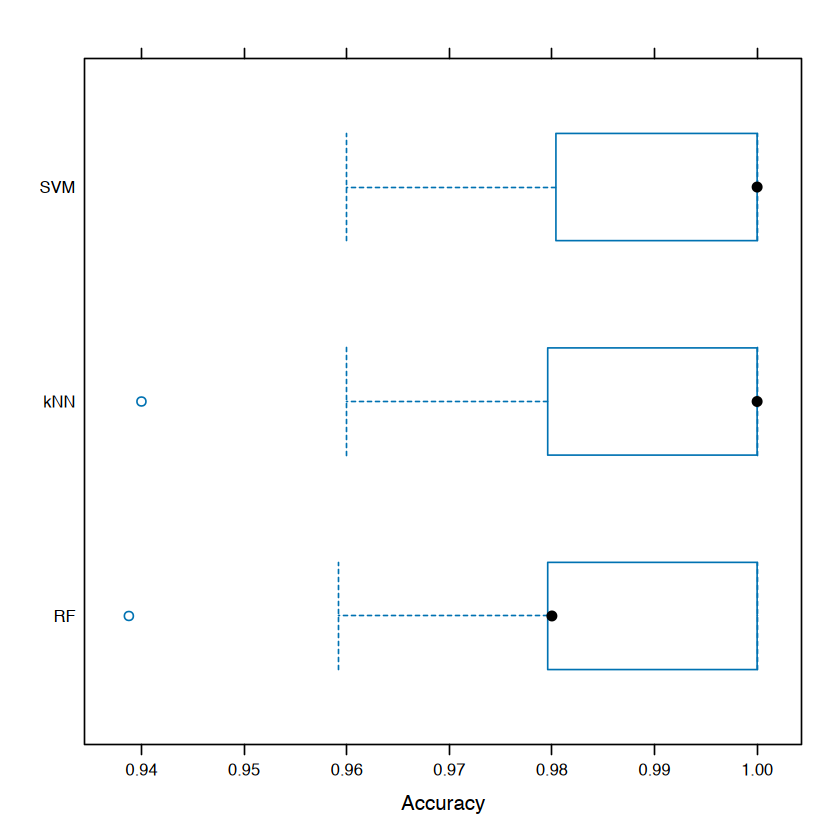

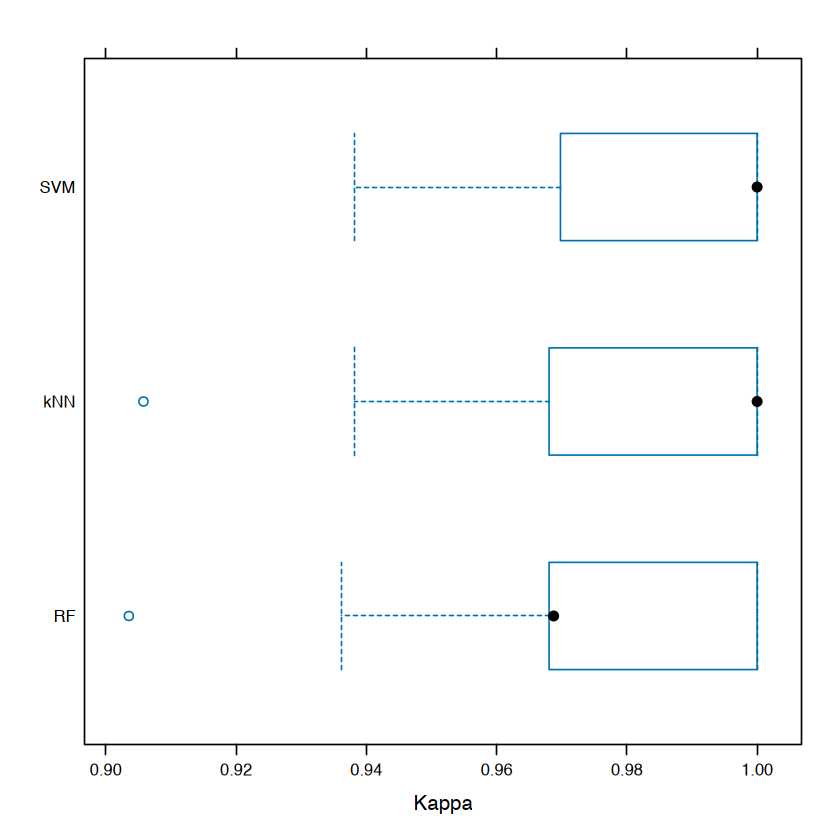

In [9]:
cat("--- 步骤一：使用123个共识基因训练最终分类器 ---\n")

# 1.1 准备训练数据
# 确保 rna_zscore_major 的列名与 rna_sample_info_major 的样本名顺序一致
stopifnot(all(colnames(rna_zscore_major) == rna_sample_info_major$Sample))

# 从Z-score矩阵中提取特征基因
train_expr <- rna_zscore_major[genes_in_at_least_two, ]

# 创建用于训练的数据框
train_data <- as.data.frame(t(train_expr))
train_data$Subtype <- rna_sample_info_major$Ensemble

# 设置交叉验证方案
# 我们将使用10折交叉验证（10-fold CV）来评估每个模型在发现队列内部的性能
train_control <- trainControl(
  method = "cv",
  number = 10,
  summaryFunction = multiClassSummary # 输出Accuracy, Kappa, F1 score等更全面的多分类指标
)

# --- 2. 训练多个不同的模型 ---
# caret 的 train 函数接口非常统一，我们只需要改变 method 参数即可

# 2.1 训练 Random Forest 模型 (作为基准)
cat("--- 正在训练 Random Forest (caret) ---\n")
model_rf <- train(
  Subtype ~ .,
  data = train_data,
  method = "rf", # 'rf' 代表 Random Forest
  trControl = train_control,
  metric = "Accuracy" # 优化的目标指标
)


# 2.2 训练 线性SVM 模型
cat("--- 正在训练 线性SVM ---\n")
model_svm <- train(
  Subtype ~ .,
  data = train_data,
  method = "svmLinear", # 'svmLinear' 代表线性SVM
  trControl = train_control,
  metric = "Accuracy"
)


# 2.3 训练 k-NN 模型
# caret 会自动帮你优化超参数 'k' (邻居的数量)
cat("--- 正在训练 k-NN ---\n")
model_knn <- train(
  Subtype ~ .,
  data = train_data,
  method = "kknn", # 'kknn' 是一个常用的k-NN实现
  trControl = train_control,
  metric = "Accuracy"
)


# --- 3. 比较模型的性能 ---
cat("\n--- 各模型在10折交叉验证中的性能比较 ---\n")

# 将所有模型的结果汇总
results <- resamples(list(RF = model_rf, SVM = model_svm, kNN = model_knn))

# 打印性能摘要
summary(results)

# 可以用箱线图更直观地比较
bwplot(results, metric = "Accuracy")
bwplot(results, metric = "Kappa")

In [10]:
# 假设 sample_info 是您包含所有样本信息的总数据框
# 假设 list_validation_zscore 是您之前准备好的验证集Z-score矩阵列表
# list_validation_zscore <- list("2020Job" = ..., "2017Jusakual" = ..., "Other_Dataset" = ...)

# 1. 定义需要提取的带有生存信息的数据集名称
survival_datasets <- c("2020Job", "2017Jusakual")

# 2. 从总信息表中筛选、选取并重命名列
survival_data_combined <- sample_info %>%
  # 步骤一：只筛选出那两个有生存信息的数据集
  filter(Study %in% survival_datasets) %>%
  # 步骤二：选取需要的列并进行重命名
  # 假设您的样本ID列名为 'SampleID'，请按需修改
  select(
    Study,
    Sample = SampleID, 
    OS_time = `Overall survival (days)`, # 注意：如果列名有空格或特殊字符，需用反引号``括起来
    OS_status = `Vital state (1=Dead)`
  ) %>%
  # 步骤三（可选但推荐）：处理缺失值
  # 确保生存时间和状态没有NA值，否则后续分析会报错
  filter(!is.na(OS_time) & !is.na(OS_status))

# 3. 检查一下整理好的数据
cat("从总表中提取并整理好的生存信息:\n")
print(head(survival_data_combined))
cat("\n")
print(table(survival_data_combined$Study))

# 4. 按照 'Study' 列将数据框分割成列表
# 这会创建一个名为 "2020Job" 和 "2017Jusakual" 的列表元素
list_validation_survival_info <- split(
  # 从数据框中移除Study列，因为信息已经包含在列表名中
  survival_data_combined[, c("Sample", "OS_time", "OS_status")], 
  survival_data_combined$Study
)

# 5. 最终检查
cat("\n最终生成的 list_validation_survival_info 结构:\n")
str(list_validation_survival_info)

cat("\n'2020Job' 数据集的前几行:\n")
print(head(list_validation_survival_info[["2020Job"]]))

cat("\n'2017Jusakual' 数据集的前几行:\n")
print(head(list_validation_survival_info[["2017Jusakual"]]))

从总表中提取并整理好的生存信息:
# A tibble: 6 × 4
  Study        Sample    OS_time OS_status
  <chr>        <chr>       <dbl>     <dbl>
1 2017Jusakual CCA_BR_1       26         1
2 2017Jusakual CCA_BR_2      566         1
3 2017Jusakual CCA_FR_1     2044         0
4 2017Jusakual CCA_FR_10    3217         0
5 2017Jusakual CCA_FR_11    3114         0
6 2017Jusakual CCA_FR_12     267         0


2017Jusakual      2020Job 
          81           76 

最终生成的 list_validation_survival_info 结构:
List of 2
 $ 2017Jusakual: tibble [81 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Sample   : chr [1:81] "CCA_BR_1" "CCA_BR_2" "CCA_FR_1" "CCA_FR_10" ...
  ..$ OS_time  : num [1:81] 26 566 2044 3217 3114 ...
  ..$ OS_status: num [1:81] 1 1 0 0 0 0 1 0 0 0 ...
 $ 2020Job     : tibble [76 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Sample   : chr [1:76] "ICC001G" "ICC002G" "ICC003G" "ICC005G" ...
  ..$ OS_time  : num [1:76] 1290 5130 210 750 2340 3630 4110 1260 120 2280 ...
  ..$ OS_status: num [1:76] 0 0 0 1 1 1 0 1 1 1 ...

'2020

In [18]:
# --- 步骤二：在每个独立的验证队列上进行预测和评估 ---

# 创建一个文件夹来保存所有验证结果的图片
if (!dir.exists("final_validation_results")) {
  dir.create("final_validation_results")
}

all_predictions_list <- list()

# 循环遍历每个验证数据集
for (dataset_name in names(list_validation_zscore)) {
  
  cat("\n======================================================\n")
  cat(">>> 正在验证:", dataset_name, "\n")
  cat("======================================================\n")
  
  # 2.1 准备验证数据
  current_validation_zscore <- list_validation_zscore[[dataset_name]]
  
  common_genes <- intersect(genes_in_at_least_two, rownames(current_validation_zscore))
  cat("分类器需要", length(genes_in_at_least_two), "个基因，当前验证集找到", length(common_genes), "个。\n")
  
  num_samples <- ncol(current_validation_zscore)
  sample_names <- colnames(current_validation_zscore)
  
  full_feature_matrix <- matrix(NA, 
                                nrow = num_samples, 
                                ncol = length(genes_in_at_least_two),
                                dimnames = list(sample_names, genes_in_at_least_two))
  
  full_feature_matrix[, common_genes] <- t(current_validation_zscore[common_genes, ])
  
  full_feature_matrix[is.na(full_feature_matrix)] <- 0
  
  validation_data_subset <- as.data.frame(full_feature_matrix)
  
  # 2.2 进行预测 
  predicted_subtypes <- predict(model_svm, validation_data_subset)
  
  prediction_results_df <- data.frame(
    Sample = rownames(validation_data_subset),
    Predicted_Subtype = predicted_subtypes
  )
  
  cat("预测完成，各亚型数量分布:\n")
  print(table(prediction_results_df$Predicted_Subtype))

  all_predictions_list[[dataset_name]] <- prediction_results_df
  
  # 2.3 分子模式验证 (热图)
  cat("--> 生成分子模式验证热图 (基于", length(common_genes), "个共同基因)...\n")
  if (length(common_genes) > 0) {
    
    heatmap_matrix <- current_validation_zscore[common_genes, ]
    
    # 1. 移除包含任何非数值（NA, NaN, Inf）的行
    matrix_clean <- heatmap_matrix[complete.cases(heatmap_matrix) & rowSums(is.finite(heatmap_matrix)) == ncol(heatmap_matrix), ]
    
    # 2. 移除方差为零的行
    if (nrow(matrix_clean) > 1) { # 必须至少有2行才能计算方差
        row_variances <- apply(matrix_clean, 1, var)
        matrix_clean <- matrix_clean[row_variances > 0, ]
    }
    
    if(nrow(matrix_clean) == 0) {
        cat("--> 警告: 在数据集 '", dataset_name, "' 中，所有共同基因都因包含NA或0方差而被移除。跳过热图生成。\n")
    } else {
        cat("--> 清洗后，用于绘制热图的基因为", nrow(matrix_clean), "个。\n")
        
        # 后续所有操作都使用清洗后的 matrix_clean
        ordered_samples <- prediction_results_df %>% arrange(Predicted_Subtype) %>% pull(Sample)
        annotation_col <- data.frame(Subtype = prediction_results_df$Predicted_Subtype)
        rownames(annotation_col) <- prediction_results_df$Sample
        
        breaksList <- seq(-3, 3, by = 0.06)
        ann_colors <- list(Subtype = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen"))
        
        png(
          file.path("final_validation_results", paste0("Heatmap_", dataset_name, ".png")),
          width = 10, height = 18, units = "in", res = 300
        )
        
        pheatmap(
          matrix_clean[, ordered_samples], # 使用清洗后的矩阵
          annotation_col = annotation_col[ordered_samples, , drop=FALSE],
          annotation_colors = ann_colors,
          cluster_cols = FALSE,
          cluster_rows = TRUE,
          show_colnames = FALSE,
          main = paste("Validation Heatmap for", dataset_name),
          color = colorRampPalette(c("navy", "white", "firebrick3"))(length(breaksList)),
          breaks = breaksList,
          border_color = NA
        )
        dev.off()
    } 
  } else {
    cat("--> 警告: 在数据集 '", dataset_name, "' 中未找到任何共同的特征基因。跳过热图生成。\n")
  }
  # =================================================================== #
  
  # 2.4 临床意义验证 (生存分析) - 这部分代码无需修改
  if (dataset_name %in% names(list_validation_survival_info)) {
    
    cat("--> 发现生存信息，进行临床意义验证...\n")
    
    current_survival_info <- list_validation_survival_info[[dataset_name]]
    survival_analysis_df <- inner_join(prediction_results_df, current_survival_info, by = "Sample")
    
    if (nrow(survival_analysis_df) > 0) {
      surv_obj <- Surv(time = survival_analysis_df$OS_time, event = survival_analysis_df$OS_status)
      fit_km <- survfit(surv_obj ~ Predicted_Subtype, data = survival_analysis_df)
      
      km_plot <- ggsurvplot(
        fit_km, data = survival_analysis_df, pval = TRUE, conf.int = TRUE,
        risk.table = TRUE, legend.title = "Predicted Subtype",
        palette = c("firebrick3", "navy", "forestgreen"),
        title = paste("Kaplan-Meier Curve for", dataset_name)
      )
      
      png(file.path("final_validation_results", paste0("Survival_", dataset_name, ".png")), width = 800, height = 960)
      print(km_plot, newpage = FALSE)
      dev.off()
      
      cat("--> 生存曲线图已保存。\n")
    } else {
      cat("--> 警告：预测结果与生存信息未能匹配到任何样本，跳过生存分析。\n")
    }
  } else {
    cat("--> 未发现生存信息，跳过生存分析。\n")
  }
}

all_predictions_df <- dplyr::bind_rows(all_predictions_list, .id = "Study")

cat("\n--- 所有验证流程执行完毕！请检查 'final_validation_results' 文件夹中的结果。 ---\n")


>>> 正在验证: 2012Andersen 
分类器需要 123 个基因，当前验证集找到 109 个。
预测完成，各亚型数量分布:

C1 C2 C3 
29 31 44 
--> 生成分子模式验证热图 (基于 109 个共同基因)...
--> 清洗后，用于绘制热图的基因为 109 个。
--> 未发现生存信息，跳过生存分析。

>>> 正在验证: 2013Sia 
分类器需要 123 个基因，当前验证集找到 113 个。
预测完成，各亚型数量分布:

C1 C2 C3 
38 75 36 
--> 生成分子模式验证热图 (基于 113 个共同基因)...
--> 清洗后，用于绘制热图的基因为 113 个。
--> 未发现生存信息，跳过生存分析。

>>> 正在验证: 2017Jusakual 
分类器需要 123 个基因，当前验证集找到 120 个。
预测完成，各亚型数量分布:

C1 C2 C3 
13 39 31 
--> 生成分子模式验证热图 (基于 120 个共同基因)...
--> 清洗后，用于绘制热图的基因为 120 个。
--> 发现生存信息，进行临床意义验证...
--> 生存曲线图已保存。

>>> 正在验证: 2020Job 
分类器需要 123 个基因，当前验证集找到 118 个。
预测完成，各亚型数量分布:

C1 C2 C3 
12 44 22 
--> 生成分子模式验证热图 (基于 118 个共同基因)...
--> 清洗后，用于绘制热图的基因为 118 个。
--> 发现生存信息，进行临床意义验证...
--> 生存曲线图已保存。

>>> 正在验证: TIGER 
分类器需要 123 个基因，当前验证集找到 121 个。
预测完成，各亚型数量分布:

C1 C2 C3 
27 30 35 
--> 生成分子模式验证热图 (基于 121 个共同基因)...
--> 清洗后，用于绘制热图的基因为 121 个。
--> 未发现生存信息，跳过生存分析。

--- 所有验证流程执行完毕！请检查 'final_validation_results' 文件夹中的结果。 ---


In [19]:
# 查看合并结果
head(all_predictions_df)

,Study,Sample,Predicted_Subtype
,<chr>,<chr>,<fct>
1,2012Andersen,GSM653074,C1
2,2012Andersen,GSM653075,C1
3,2012Andersen,GSM653076,C1
4,2012Andersen,GSM653077,C3
5,2012Andersen,GSM653078,C1
6,2012Andersen,GSM653079,C1


--- 正在独立调试数据集: 2012Andersen ---
用于绘图的最终基因数量为: 109 
--- 正在尝试直接绘图... ---
--- 调试代码执行完毕。---


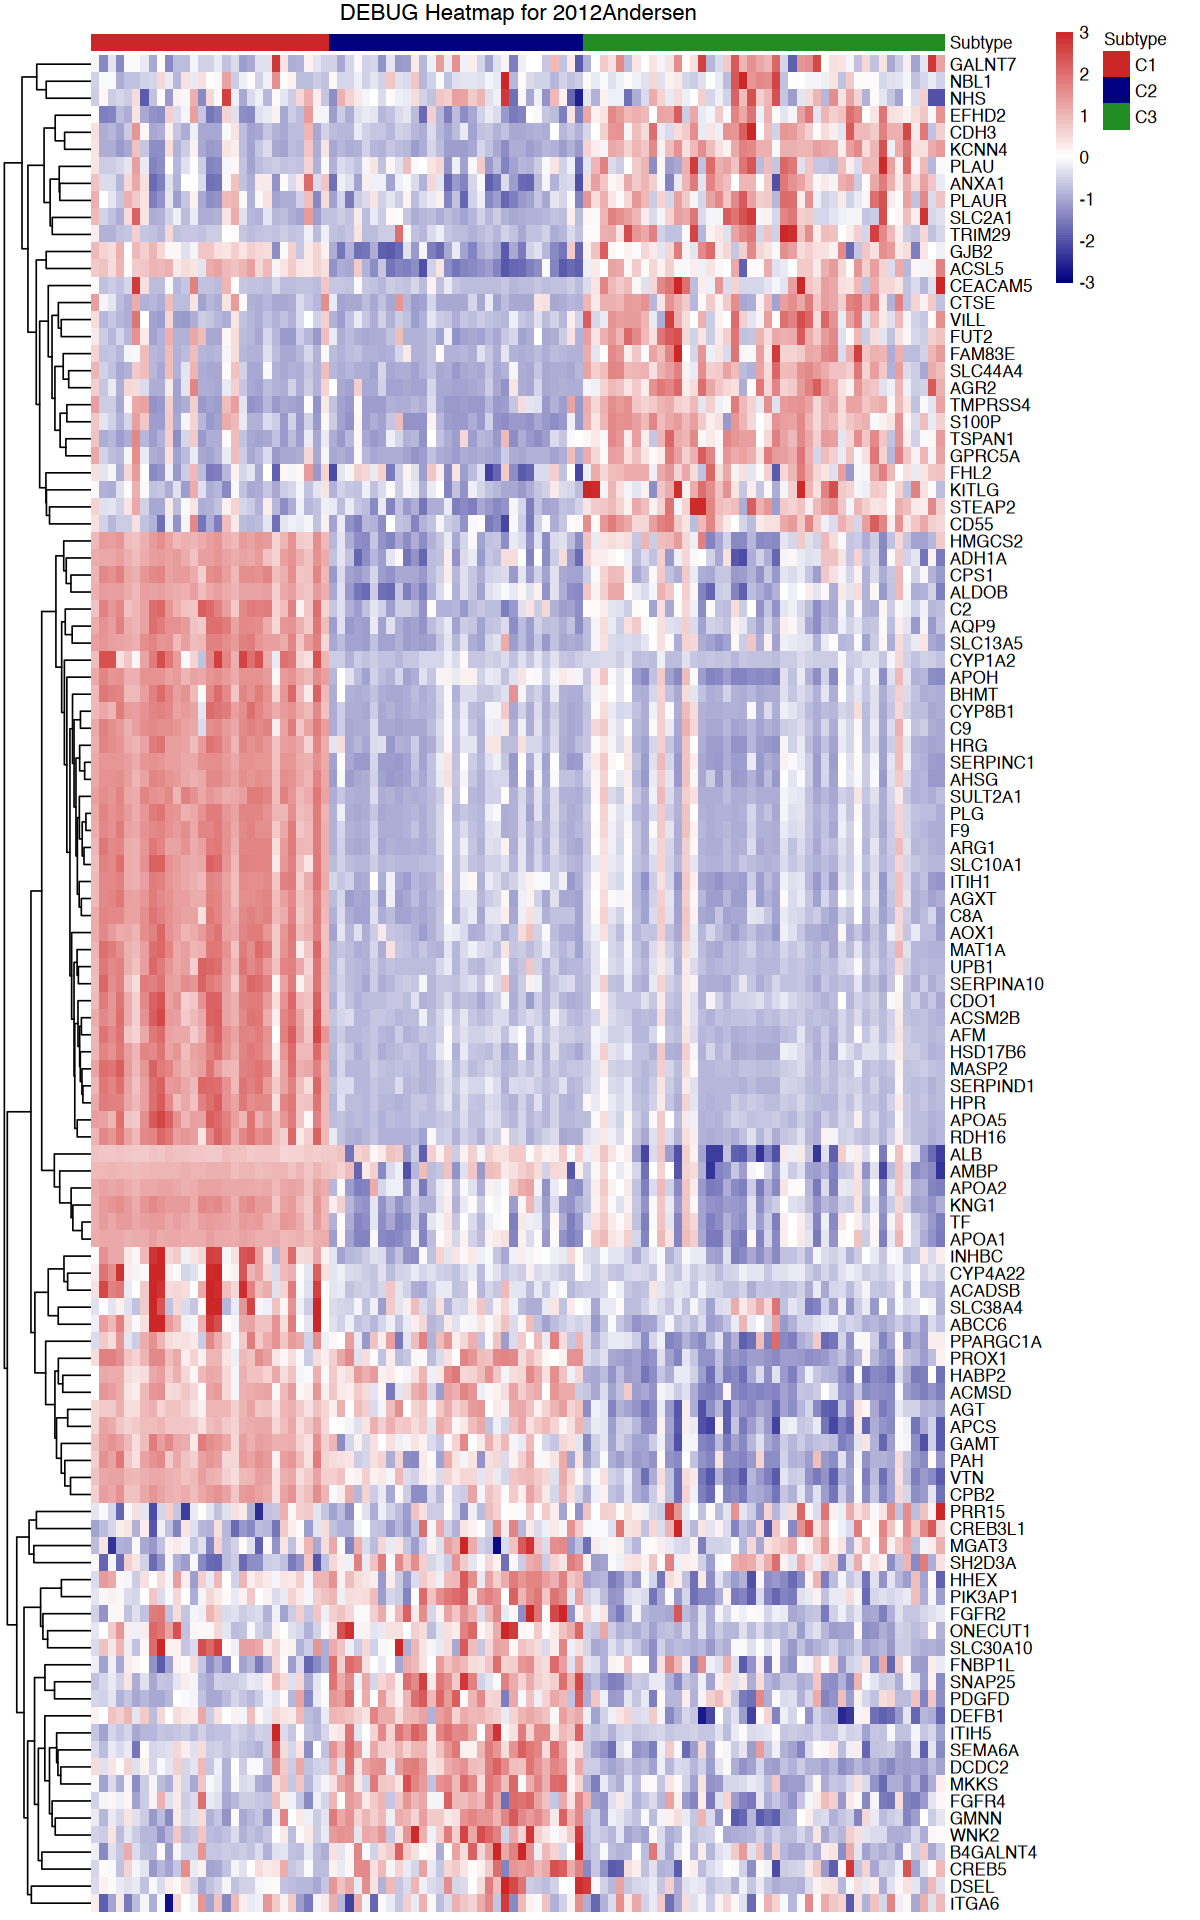

In [21]:
# --- 独立调试脚本 ---

# 1. 加载必要的包
library(dplyr)
library(pheatmap)

# 2. 准备所需的核心数据对象
# (请确保在运行此脚本前，您的环境中已经加载了这些对象)
# list_validation_zscore
# genes_in_at_least_two
# all_predictions_list  (您在上一步已经生成)

# --- 让我们开始调试 ---

# 3. 设定我们要调试的数据集名称
dataset_name <- "2012Andersen"
cat("--- 正在独立调试数据集:", dataset_name, "---\n")

# 4. 提取与该数据集相关的所有数据
current_validation_zscore <- list_validation_zscore[[dataset_name]]
prediction_results_df <- all_predictions_list[[dataset_name]]
common_genes <- intersect(genes_in_at_least_two, rownames(current_validation_zscore))

# 5. 准备用于绘图的矩阵 (包含清洗步骤)
heatmap_matrix <- current_validation_zscore[common_genes, ]

matrix_clean <- heatmap_matrix[complete.cases(heatmap_matrix) & rowSums(is.finite(heatmap_matrix)) == ncol(heatmap_matrix), ]
if (nrow(matrix_clean) > 1) {
    row_variances <- apply(matrix_clean, 1, var)
    matrix_clean <- matrix_clean[row_variances > 0, ]
}

cat("用于绘图的最终基因数量为:", nrow(matrix_clean), "\n")


# 6. 准备样本排序和注释信息
ordered_samples <- prediction_results_df %>% arrange(Predicted_Subtype) %>% pull(Sample)
annotation_col <- data.frame(Subtype = prediction_results_df$Predicted_Subtype)
rownames(annotation_col) <- prediction_results_df$Sample

# 7. 准备颜色和断点
breaksList <- seq(-3, 3, by = 0.06)
ann_colors <- list(Subtype = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen"))

# 8. **核心调试步骤：直接调用pheatmap函数进行绘图**
# 我们去掉了 png() 和 dev.off()，让图形直接输出到R的绘图窗口
cat("--- 正在尝试直接绘图... ---\n")
options(repr.plot.width=10, repr.plot.height=16)
pheatmap(
  matrix_clean[, ordered_samples],
  annotation_col = annotation_col[ordered_samples, , drop=FALSE],
  annotation_colors = ann_colors,
  cluster_cols = FALSE,
  cluster_rows = TRUE,
  show_colnames = FALSE,
  main = paste("DEBUG Heatmap for", dataset_name),
  color = colorRampPalette(c("navy", "white", "firebrick3"))(length(breaksList)),
  breaks = breaksList,
  border_color = NA,
)

cat("--- 调试代码执行完毕。---\n")

In [14]:
sample_info_with_predictions <- sample_info %>%
  left_join(all_predictions_df, by = c("SampleID" = "Sample"))

In [15]:
write.csv2(sample_info_with_predictions, "sample_info_with_predictions.csv", row.names = FALSE)

In [16]:
save(model_knn, model_rf, model_svm, all_predictions_df,
     file = "./4-Validation/final_trained_models.rds")
saveRDS(model_svm, file = "iCCA_Subtype_SVM_Classifier.rds")

## **CCLE validation**

In [23]:
# --- 0. 环境准备：加载所需R包 ---
# 如果您尚未安装这些包，请先运行 install.packages(...)
library(dplyr)       # 用于数据整理
library(readr)       # 用于高效读取CSV文件
library(tidyr)       # 用于数据格式转换
library(ggplot2)     # 用于数据可视化
library(caret)       # 加载 train/predict 函数所需环境
library(e1071)       # SVM算法的依赖包

In [6]:
load(file = "./4-Validation/selected_signature_genes.rds")

In [7]:
file_expression <- "./4-Validation/OmicsExpressionTPMLogp1HumanAllGenes.csv"
file_drugs <- "./4-Validation/Drug_sensitivity_AUC_(PRISM_Repurposing_Secondary_Screen).csv"
file_metadata <- "./4-Validation/Model.csv"
file_classifier <- "./4-Validation/iCCA_Subtype_SVM_Classifier.rds"

In [ ]:
# --- 1. 加载所有数据和模型 ---
cat("--- 步骤一：正在加载所有数据文件和分类器模型... ---\n")

# 1.1 加载细胞系元数据
meta_df <- read_csv(file_metadata)
dim(meta_df)
head(meta_df)

--- 步骤一：正在加载所有数据文件和分类器模型... ---


Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Rows: 2116 Columns: 49
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (41): ModelID, PatientID, CellLineName, StrippedCellLineName, DepmapMode...
dbl  (4): Age, PatientTumorGrade, WTSIMasterCellID, COSMICID
lgl  (4): TissueOrigin, StagingSystem, SerumFreeMedia, PediatricModelType

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 2116   49

ModelID,PatientID,CellLineName,StrippedCellLineName,DepmapModelType,OncotreeLineage,OncotreePrimaryDisease,OncotreeSubtype,OncotreeCode,PatientSubtypeFeatures,⋯,PublicComments,CCLEName,HCMIID,PediatricModelType,ModelAvailableInDbgap,ModelSubtypeFeatures,WTSIMasterCellID,SangerModelID,COSMICID,ModelIDAlias
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>
ACH-000001,PT-gj46wT,NIH:OVCAR-3,NIHOVCAR3,HGSOC,Ovary/Fallopian Tube,Ovarian Epithelial Tumor,High-Grade Serous Ovarian Cancer,HGSOC,NA,⋯,NA,NIHOVCAR3_OVARY,NA,FALSE,Approved for public sharing - CCLE,NA,2201,SIDM00105,905933,NA
ACH-000002,PT-5qa3uk,HL-60,HL60,AMLMRC,Myeloid,Acute Myeloid Leukemia,AML with Myelodysplasia-Related Changes,AMLMRC,"TP53(del), CDKN2A and NRAS mutations [PubMed=288488], No PML-RARA fusion",⋯,NA,HL60_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NA,TRUE,Approved for public sharing - CCLE,"NRAS, BCOR and CDKN2A",55,SIDM00829,905938,NA
ACH-000003,PT-puKIyc,CACO2,CACO2,COAD,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,COAD,NA,⋯,NA,CACO2_LARGE_INTESTINE,NA,FALSE,Approved for public sharing - CCLE,NA,NA,SIDM00891,NA,NA
ACH-000004,PT-q4K2cp,HEL,HEL,AMLNOS,Myeloid,Acute Myeloid Leukemia,"AML, NOS",AMLNOS,JAK2 and TP53 mutations,⋯,NA,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NA,TRUE,Approved for public sharing - CCLE,JAK2 and TP53,783,SIDM00594,907053,NA
ACH-000005,PT-q4K2cp,HEL 92.1.7,HEL9217,AML,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,AML,JAK2 and TP53 mutations,⋯,NA,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NA,TRUE,Approved for public sharing - CCLE,NA,NA,SIDM00593,NA,NA
ACH-000006,PT-ej13Dz,MONO-MAC-6,MONOMAC6,AML,Myeloid,Acute Myeloid Leukemia,Acute Myeloid Leukemia,AML,"KMT2A-MLLT3, TP53 Arg273His",⋯,NA,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,NA,TRUE,Approved for public sharing - CCLE,"KMT2A::MLLT3, TP53, ASXL1 and U2AF1",2167,SIDM01023,908148,NA


In [9]:
# 1.2 筛选iCCA细胞系
# 根据您之前的截图，我们使用 OncotreeSubtype 列进行筛选
# DepMap ID 在 Model.csv 中列名为 `ModelID`
icca_cell_lines <- meta_df %>%
  filter(OncotreeSubtype == "Intrahepatic Cholangiocarcinoma") %>%
  pull(ModelID) # ModelID 列对应 DepMap_ID

cat("筛选到", length(icca_cell_lines), "个iCCA相关的细胞系。\n")

筛选到 29 个iCCA相关的细胞系。


In [10]:
# 1.3 加载基因表达数据
# DepMap的表达矩阵第一列是基因名，我们需要将其设为行名
expr_df <- read_csv(file_expression)
dim(expr_df)
head(expr_df)

New names:
• `` -> `...1`
Rows: 1739 Columns: 60653
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr     (2): ProfileID, ModelID
dbl (60650): ...1, TSPAN6 (7105), TNMD (64102), DPM1 (8813), SCYL3 (57147), ...
lgl     (1): is_default_entry

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1]  1739 60653

...1,ProfileID,is_default_entry,ModelID,TSPAN6 (7105),TNMD (64102),DPM1 (8813),SCYL3 (57147),FIRRM (55732),FGR (2268),⋯,ENSG00000288716.1,ENSG00000288717.1,ENSG00000288718.1,ENSG00000288719.1,ENSG00000288720.1,ENSG00000288721.1,F8A1 (8263),ENSG00000288723.1,ENSG00000288724.1,ENSG00000288725.1
<dbl>,<chr>,<lgl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,PR-AdBjpG,TRUE,ACH-001113,4.956577,0.000000,7.577648,3.179411,4.765742,0.03748344,⋯,0,0.2440200,0.0000000,0.03146013,0.33676897,1.1208496,4.315653,0.00000000,0,0.00000000
1,PR-I2AzwG,TRUE,ACH-001289,4.954992,0.617243,7.334747,2.783576,3.736280,0.00000000,⋯,0,0.5146313,0.0000000,0.01138257,0.18620768,0.5129247,4.251060,0.00000000,0,0.06380111
2,PR-5ekAAC,TRUE,ACH-001339,3.421952,0.000000,7.546069,2.615880,4.476233,0.06457111,⋯,0,0.0000000,0.1041259,0.00000000,0.17148355,0.2384763,2.783448,0.04857659,0,0.00000000
3,PR-JYaayr,FALSE,ACH-001619,5.196729,0.000000,6.362268,2.144996,3.087183,0.03600107,⋯,0,0.0000000,0.0000000,0.00000000,0.11156688,0.1912708,5.106595,0.00000000,0,0.00000000
4,PR-DuAy1L,TRUE,ACH-001979,4.651643,0.000000,5.946408,2.454515,1.852111,0.00000000,⋯,0,0.1965982,0.0000000,0.00000000,0.11339646,0.2514489,4.661556,0.00000000,0,0.04744765
5,PR-pGHJuj,TRUE,ACH-002438,4.336705,0.000000,6.879387,2.262824,3.256491,0.00000000,⋯,0,0.0000000,0.2256686,0.00000000,0.01715227,0.4643933,6.202939,0.00000000,0,0.00000000


In [11]:
# 1.3.1 清理基因名
cleaned_colnames <- gsub(" \\(\\d+\\)", "", colnames(expr_df))
colnames(expr_df) <- cleaned_colnames

# 1.3.2 **两步法确保细胞系唯一性 
expr_df_unique <- expr_df %>%
  # 第一步：优先筛选官方推荐的数据
  filter(is_default_entry == TRUE) %>%
  # 第二步：强制去重，确保每个ModelID只出现一次
  # .keep_all = TRUE 表示保留该行的所有列
  distinct(ModelID, .keep_all = TRUE)
cat("Original rows:", nrow(expr_df), "\n")
cat("Rows after filtering and de-duplication:", nrow(expr_df_unique), "\n")

Original rows: 1739 
Rows after filtering and de-duplication: 1684 


In [12]:
# 1.3.3 将干净的数据整理成最终的 "基因 x 样本" 矩阵
expr_matrix_final <- expr_df_unique %>%
  # 将现在保证唯一的 ModelID 设为行名
  column_to_rownames(var = "ModelID") %>%
  select(TSPAN6:last_col()) %>%
  t()

# 1.3.4 检查最终结果
cat("\nProcessing complete. Final matrix dimensions:\n")
print(dim(expr_matrix_final))
head(expr_matrix_final[, 1:5])


Processing complete. Final matrix dimensions:
[1] 60649  1684


,ACH-001113,ACH-001289,ACH-001339,ACH-001979,ACH-002438
TSPAN6,4.95657712,4.954992,3.42195170,4.651643,4.336705
TNMD,0.00000000,0.617243,0.00000000,0.000000,0.000000
DPM1,7.57764786,7.334747,7.54606872,5.946408,6.879387
SCYL3,3.17941073,2.783576,2.61588001,2.454515,2.262824
FIRRM,4.76574159,3.736280,4.47623261,1.852111,3.256491
FGR,0.03748344,0.000000,0.06457111,0.000000,0.000000


In [13]:
# 1.3.5 保留这些iCCA细胞系
# 首先找到这些细胞系在表达矩阵列名中的交集
icca_cell_lines_in_expr <- intersect(icca_cell_lines, colnames(expr_matrix_final))
ccle_log_tpm <- expr_matrix_final[, icca_cell_lines_in_expr]

cat("其中", ncol(ccle_log_tpm), "个细胞系在表达数据中存在。\n")

其中 28 个细胞系在表达数据中存在。


In [14]:
# 1.4 加载药物敏感性数据 (AUC)
drug_auc_df <- read_csv(file_drugs)
dim(drug_auc_df)
head(drug_auc_df)

New names:
• `` -> `...1`
Rows: 480 Columns: 1451
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (1): ...1
dbl (1450): 8-BROMO-CGMP (BRD:BRD-A00077618-236-07-6), NORETYNODREL (BRD:BRD...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1]  480 1451

...1,8-BROMO-CGMP (BRD:BRD-A00077618-236-07-6),NORETYNODREL (BRD:BRD-A00758722-001-04-9),PREDNISOLONE-ACETATE (BRD:BRD-A01643550-001-04-9),BETAMETHASONE (BRD:BRD-A02180903-001-04-5),MEPIVACAINE (BRD:BRD-A03216249-003-24-3),XL888 (BRD:BRD-A03506276-001-01-5),METOPROLOL (BRD:BRD-A03623303-045-09-5),METHSCOPOLAMINE (BRD:BRD-A03932035-004-04-3),LAPPACONITE (BRD:BRD-A05906449-004-01-1),⋯,LORLATINIB (BRD:BRD-K99879819-001-02-1),HEXYLRESORCINOL (BRD:BRD-K99946902-001-07-5),BOSULIF (BRD:BRD-K99964838-001-11-9),AMMONIUM-LACTATE (BRD:BRD-M29182745-001-01-4),NEMONAPRIDE (BRD:BRD-M80207679-001-01-5),CROMAKALIM (BRD:BRD-M89827113-001-01-5),EFONIDIPINE-MONOETHANOLATE (BRD:BRD-M92675308-003-07-1),DICHLOROACETATE (BRD:BRD-M97302542-001-04-4),TYLOXAPOL (BRD:BRD-U25960968-000-01-9),SEVELAMER (BRD:BRD-U45393375-000-01-6)
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ACH-000007,NA,0.9036443,NA,0.9385374,NA,0.5120505,NA,NA,0.8205047,⋯,NA,0.8269144,NA,NA,NA,NA,NA,NA,NA,NA
ACH-000008,NA,0.8807564,NA,NA,NA,0.5153781,NA,NA,0.8624941,⋯,0.9913449,0.9060888,NA,NA,NA,NA,0.9097623,NA,NA,NA
ACH-000011,0.999997,0.9514126,NA,NA,NA,0.4731331,NA,0.8871717,0.8108388,⋯,0.9377615,NA,0.8124619,NA,NA,NA,0.9158117,NA,NA,NA
ACH-000012,NA,0.8772781,0.9330896,0.8374609,NA,0.5580897,NA,0.9615860,0.8254347,⋯,NA,NA,0.7137057,NA,NA,NA,0.9851307,NA,NA,NA
ACH-000013,NA,0.9772097,NA,NA,NA,0.2766165,NA,0.8673210,0.7593041,⋯,NA,NA,NA,NA,NA,NA,NA,0.8958233,0.9742335,NA
ACH-000014,NA,0.9420683,NA,NA,NA,0.4813725,NA,NA,0.8618699,⋯,0.9611979,0.9243131,0.9069175,NA,NA,NA,0.9509845,0.9677264,NA,NA


In [15]:
# 1.4.1 将数据从“宽格式”转换为“长格式”
drug_auc_long <- drug_auc_df %>%
  # 步骤 2.1: 重命名第一列，给它一个有意义的名字
  rename(DepMap_ID = ...1) %>%
  # 步骤 2.2: 使用 pivot_longer 进行转换
  pivot_longer(
    cols = -DepMap_ID,              # 选择除了DepMap_ID之外的所有列进行转换
    names_to = "Drug",              # 新建一列名为"Drug"，用于存放原来的列名（药物名）
    values_to = "AUC"               # 新建一列名为"AUC"，用于存放原来的数值
  ) %>%
  # 步骤 2.3 (推荐): 清理药物名称
  # 例如："PREDNISOLONE-ACETATE (BRD:BRD-A01643550-001-04-9)" -> "PREDNISOLONE-ACETATE"
  mutate(Drug = gsub(" \\(.*\\)", "", Drug)) %>%
  # 步骤 2.4 (推荐): 移除AUC值为NA的行
  # NA值代表该细胞系没有用该药物做实验，在分析中没有用处
  filter(!is.na(AUC))

# 1.4.2 查看转换后的“长格式”数据
cat("--- 数据已成功转换为长格式 ---\n")
print(head(drug_auc_long))

cat("\n总行数:", nrow(drug_auc_long), "\n")

--- 数据已成功转换为长格式 ---
# A tibble: 6 × 3
  DepMap_ID  Drug            AUC
  <chr>      <chr>         <dbl>
1 ACH-000007 NORETYNODREL  0.904
2 ACH-000007 BETAMETHASONE 0.939
3 ACH-000007 XL888         0.512
4 ACH-000007 LAPPACONITE   0.821
5 ACH-000007 TERFENADINE   0.881
6 ACH-000007 SB-218078     0.709

总行数: 393925 


In [16]:
# 1.5 加载您训练好的SVM分类器
model_svm <- readRDS(file_classifier)

cat("所有数据加载完毕。\n")

所有数据加载完毕。


In [17]:
load(file =  "./1-Clustering/data/combined_expr_after_correction.rds")
# 1. 定义主要分型
major_subtypes <- c("C1", "C2", "C3")
# 2. 筛选出只包含主要分型的样本信息
rna_sample_info_major <- sample_cluster %>%
  filter(Ensemble %in% major_subtypes)
# **非常重要**：确保factor的levels也被更新，去掉不再存在的中间态level
rna_sample_info_major$Ensemble <- factor(rna_sample_info_major$Ensemble)

# 3. 根据筛选后的样本信息，对Z-score矩阵进行子集化
# 确保样本顺序和信息表一致
samples_to_keep <- rna_sample_info_major$Sample
corrected_expr_limma_major <- corrected_expr_limma[, samples_to_keep]

In [18]:
# --- 2. 预处理CCLE表达数据 ---
cat("--- 步骤三：正在对CCLE数据进行Z-score标准化... ---\n")

# 您需要有一个【未经Z-score标准化】的、只包含C1,C2,C3主要分型的
# log转换后的发现队列表达矩阵。
# 假设这个矩阵名为 corrected_expr_limma_major (基因 x 样本)

# 2.1 从【未经Z-score的】发现队列中，计算每个签名基因的均值和标准差
cat("--> 正在从原始发现队列计算标准化参数 (mean/sd)...\n")
discovery_means_raw <- apply(corrected_expr_limma_major[genes_in_at_least_two, ], 1, mean)
discovery_sds_raw   <- apply(corrected_expr_limma_major[genes_in_at_least_two, ], 1, sd)

# 2.2 找到CCLE数据中也存在的签名基因
common_genes_for_zscore <- intersect(genes_in_at_least_two, rownames(ccle_log_tpm))
cat("签名基因与CCLE表达谱共有", length(common_genes_for_zscore), "个基因。\n")

# 2.3 使用【正确的】均值和标准差对CCLE数据应用Z-score转换
ccle_subset_logtpm <- ccle_log_tpm[common_genes_for_zscore, ]
ccle_zscore <- (ccle_subset_logtpm - discovery_means_raw[common_genes_for_zscore]) / discovery_sds_raw[common_genes_for_zscore]

cat("Z-score标准化完成。\n")

--- 步骤三：正在对CCLE数据进行Z-score标准化... ---
--> 正在从原始发现队列计算标准化参数 (mean/sd)...
签名基因与CCLE表达谱共有 123 个基因。
Z-score标准化完成。


In [19]:
# --- 4. 预测细胞系的亚型 ---
cat("--- 步骤四：正在使用SVM分类器预测细胞系亚型... ---\n")

# 准备用于预测的数据框，逻辑与验证循环完全一致
num_samples_ccle <- ncol(ccle_zscore)
sample_names_ccle <- colnames(ccle_zscore)

full_feature_matrix_ccle <- matrix(0, 
                                   nrow = num_samples_ccle, 
                                   ncol = length(genes_in_at_least_two),
                                   dimnames = list(sample_names_ccle, genes_in_at_least_two))

full_feature_matrix_ccle[, common_genes_for_zscore] <- t(ccle_zscore)

ccle_predict_data <- as.data.frame(full_feature_matrix_ccle)

# 进行预测
predicted_ccle_subtypes <- predict(model_svm, ccle_predict_data)

# 整理预测结果
predictions_ccle_df <- data.frame(
  DepMap_ID = sample_names_ccle,
  Predicted_Subtype = predicted_ccle_subtypes
)

cat("细胞系亚型预测完成，分布如下:\n")
print(table(predictions_ccle_df$Predicted_Subtype))

--- 步骤四：正在使用SVM分类器预测细胞系亚型... ---


细胞系亚型预测完成，分布如下:

C1 C2 C3 
 0  6 22 


--- 正在为CCLE细胞系预测结果生成热图... ---


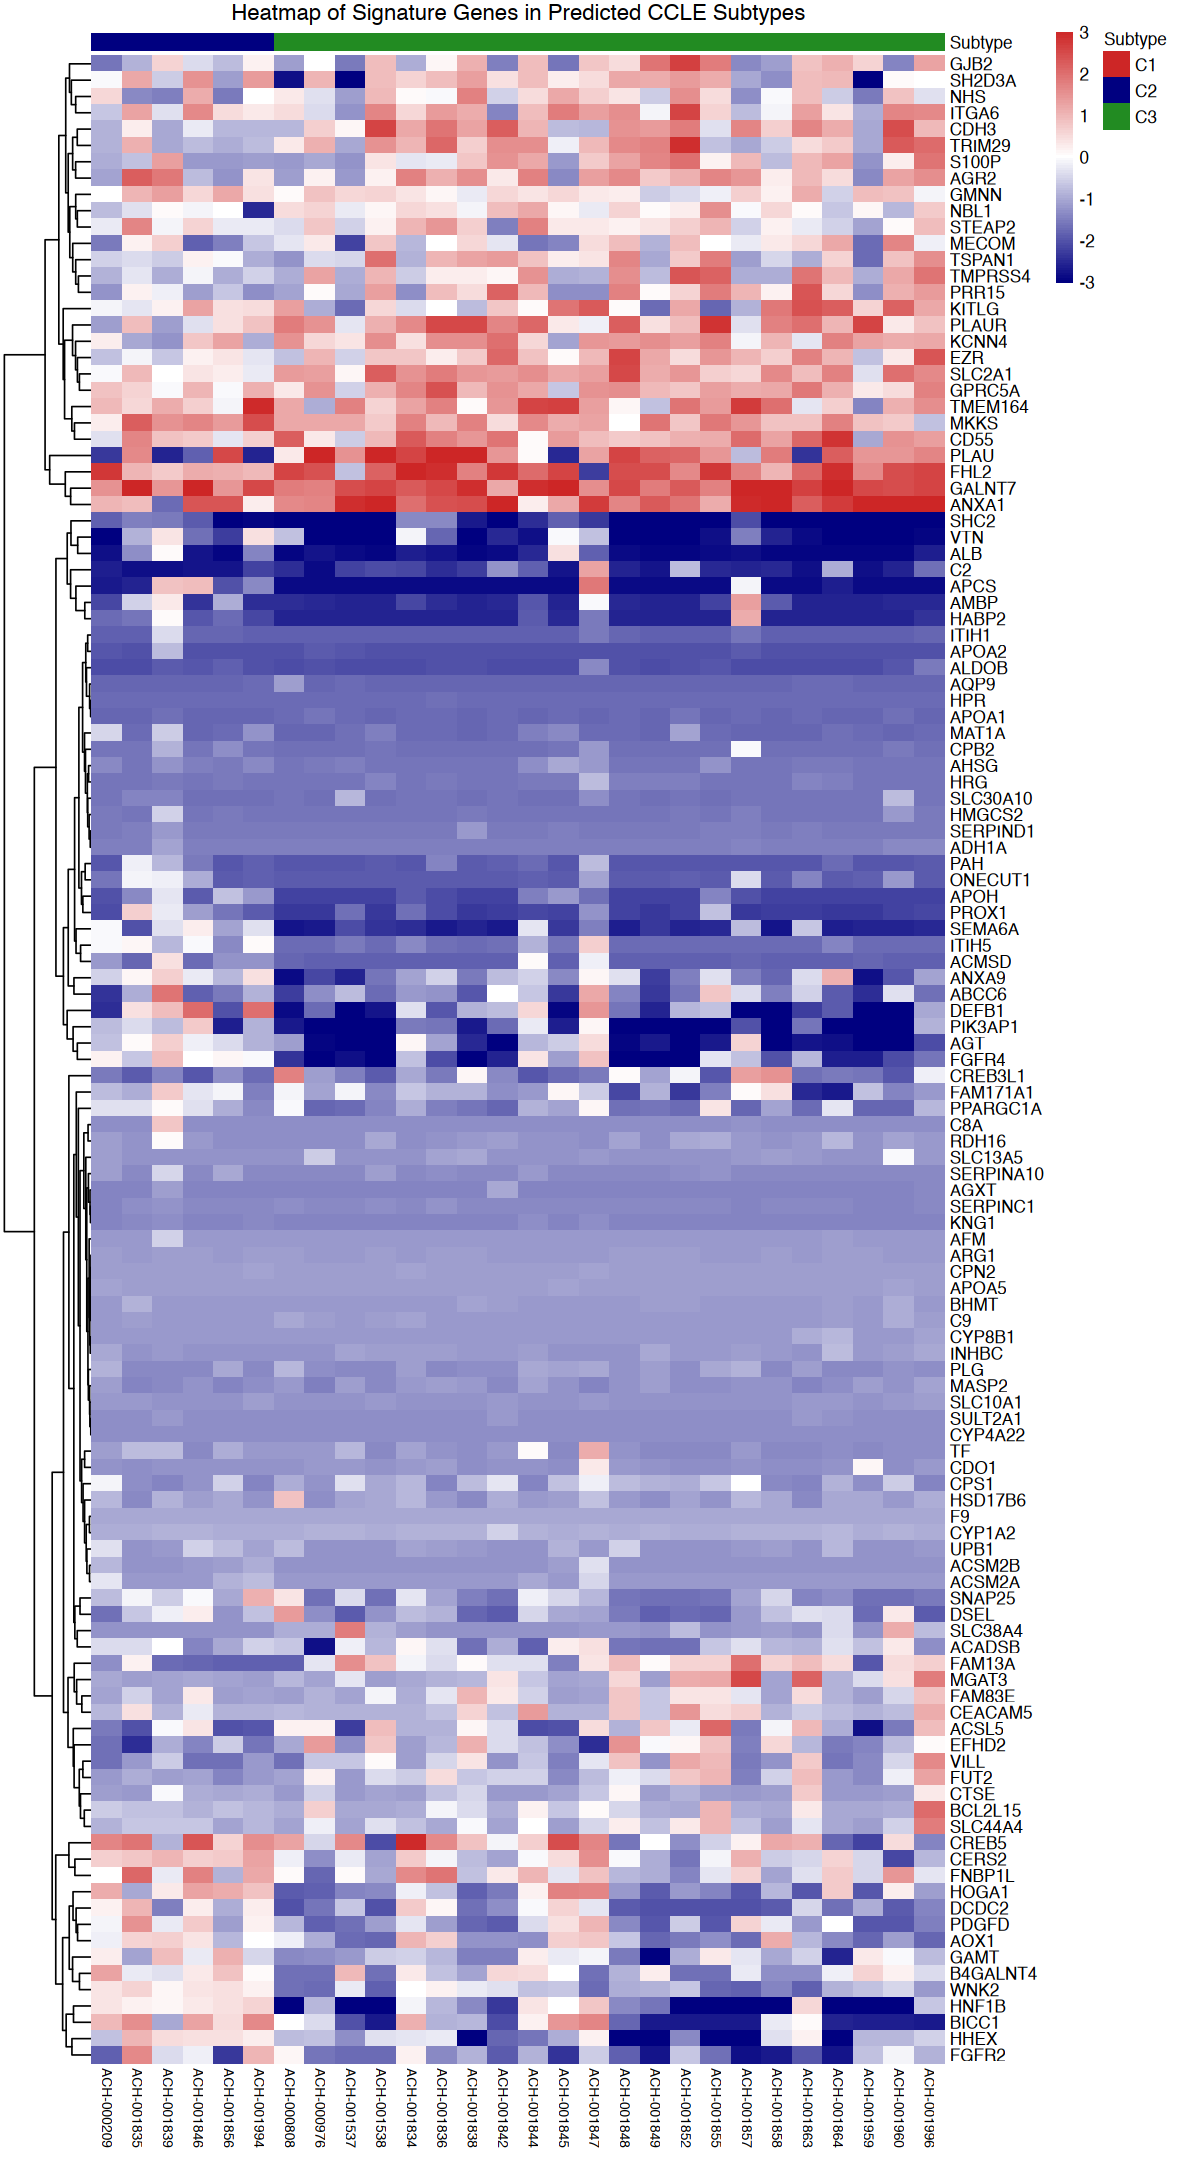

In [22]:
# 加载必要的包
library(pheatmap)
library(dplyr)

# --- 假设您的环境中已有这些对象 ---
# ccle_zscore: 经过您发现队列的均值和方差标准化后的CCLE Z-score矩阵
# predictions_ccle_df: 包含'DepMap_ID'和'Predicted_Subtype'列的预测结果数据框
# genes_in_at_least_two: 您的123个共识基因签名

# --- 1. 准备绘图所需的数据 ---

# 1.1 从CCLE Z-score矩阵中提取用于绘图的基因和样本
# 确保只使用在CCLE数据中实际存在的签名基因
common_genes_in_ccle <- intersect(genes_in_at_least_two, rownames(ccle_zscore))
heatmap_matrix_ccle <- ccle_zscore[common_genes_in_ccle, predictions_ccle_df$DepMap_ID]

# 1.2 准备样本注释和排序
# 按照预测出的亚型对样本进行排序
ordered_samples_ccle <- predictions_ccle_df %>% arrange(Predicted_Subtype) %>% pull(DepMap_ID)
annotation_col_ccle <- data.frame(Subtype = predictions_ccle_df$Predicted_Subtype)
rownames(annotation_col_ccle) <- predictions_ccle_df$DepMap_ID

# 1.3 准备颜色和断点
breaksList <- seq(-3, 3, by = 0.06)
ann_colors <- list(Subtype = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen"))

# --- 2. 绘制热图 ---
cat("--- 正在为CCLE细胞系预测结果生成热图... ---\n")
options(repr.plot.width=10, repr.plot.height=18)
pheatmap(
  heatmap_matrix_ccle[, ordered_samples_ccle], # 使用排序后的矩阵
  annotation_col = annotation_col_ccle[ordered_samples_ccle, , drop=FALSE],
  annotation_colors = ann_colors,
  cluster_cols = FALSE, # 因为已经手动排序
  cluster_rows = TRUE,
  show_colnames = TRUE,  # 细胞系数量不多，可以显示名字
  fontsize_col = 8,      # 调整列名字体大小
  main = "Heatmap of Signature Genes in Predicted CCLE Subtypes",
  color = colorRampPalette(c("navy", "white", "firebrick3"))(length(breaksList)),
  breaks = breaksList,
  border_color = NA
)

In [25]:
drug_data_with_subtypes <- inner_join(predictions_ccle_df, drug_auc_long, by = "DepMap_ID")
head(drug_data_with_subtypes)
dim(drug_data_with_subtypes)

,DepMap_ID,Predicted_Subtype,Drug,AUC
,<chr>,<fct>,<chr>,<dbl>
1,ACH-000209,C2,BETAMETHASONE,0.9084816
2,ACH-000209,C2,MEPIVACAINE,0.8925421
3,ACH-000209,C2,XL888,0.7020316
4,ACH-000209,C2,SB-218078,0.7223431
5,ACH-000209,C2,DICLAZURIL,0.9912168
6,ACH-000209,C2,MONENSIN,0.9644652


[1] 2397    4

In [38]:
length(unique(drug_data_with_subtypes$DepMap_ID))

[1] 3

In [41]:
table(drug_data_with_subtypes$DepMap_ID, drug_data_with_subtypes$Predicted_Subtype)

            
              C1  C2  C3
  ACH-000209   0 731   0
  ACH-000808   0   0 746
  ACH-000976   0   0 920

In [28]:
write.csv2(drug_data_with_subtypes, "./4-Validation/CCLE_drug_data_with_predicted_subtypes.csv", row.names = FALSE)

In [26]:
# 加载必要的包
library(dplyr)
library(ggplot2)

# --- 假设您的环境中已有 drug_data_with_subtypes 数据框 ---
# 它包含 DepMap_ID, Predicted_Subtype, name (药物名), auc (药敏值) 等列

# --- 1. 计算每个亚型中每种药物的平均敏感性 ---
# 由于C1亚型只有一个细胞系，无法计算有意义的平均值和差异，我们主要关注C2和C3
# 我们同时要求一种药物在某个亚型中至少被测试过2次，结果才更可靠
drug_summary <- drug_data_with_subtypes %>%
  filter(Predicted_Subtype %in% c("C2", "C3")) %>%
  group_by(Predicted_Subtype, Drug) %>%
  summarise(
    mean_auc = mean(AUC, na.rm = TRUE),
    n = n() # 计算测试了多少个细胞系
  ) %>%
  filter(n >= 2) %>% # 只保留在亚型中至少测试过2个细胞系的药物
  ungroup()

# 查看计算结果
head(drug_summary)

`summarise()` has grouped output by 'Predicted_Subtype'. You can override using
the `.groups` argument.


Predicted_Subtype,Drug,mean_auc,n
<fct>,<chr>,<dbl>,<int>
C2,BRIGATINIB,0.9216451,2
C3,(+)-CAMPTOTHECIN,0.5358074,2
C3,1-NAPHTHYL-PP1,0.8517485,2
C3,1-PHENYLBIGUANIDE,0.9091425,2
C3,10-DEACETYLBACCATIN,0.8310304,2
C3,10-HYDROXYCAMPTOTHECIN,0.3162054,2


In [33]:
# --- 2. 筛选出每个亚型最敏感和最耐药的药物 ---
# 您可以调整 n 的值来决定要展示多少种药物
top_n_drugs <- 5

# 筛选C3亚型的Top药物
c3_drugs <- drug_summary %>%
  filter(Predicted_Subtype == "C3") %>%
  arrange(mean_auc) # 按平均AUC升序排列
c3_sensitive <- head(c3_drugs$Drug, top_n_drugs)
c3_resistant <- tail(c3_drugs$Drug, top_n_drugs)

# 筛选C2亚型的Top药物
c2_drugs <- drug_summary %>%
  filter(Predicted_Subtype == "C2") %>%
  arrange(mean_auc)
c2_sensitive <- head(c2_drugs$Drug, top_n_drugs)
c2_resistant <- tail(c2_drugs$Drug, top_n_drugs)

# 将所有筛选出的药物合并成一个最终列表
c3_drugs_to_plot <- unique(c(c3_sensitive, c3_resistant))
print(c3_drugs_to_plot)
c2_drugs_to_plot <- unique(c(c2_sensitive, c2_resistant))
print(c2_drugs_to_plot)
drugs_to_plot <- unique(c(c3_sensitive, c3_resistant, c2_sensitive, c2_resistant))
cat("--- 根据数据筛选出以下药物进行可视化 ---\n")
print(drugs_to_plot)

 [1] "TRIPTOLIDE"           "ECHINOMYCIN"          "DOLASTATIN-10"       
 [4] "ROMIDEPSIN"           "SEPANTRONIUM BROMIDE" "CP-724714"           
 [7] "ELACRIDAR"            "ASP-7487"             "ALPELISIB"           
[10] "RUXOLITINIB"         
[1] "BRIGATINIB"
--- 根据数据筛选出以下药物进行可视化 ---
 [1] "TRIPTOLIDE"           "ECHINOMYCIN"          "DOLASTATIN-10"       
 [4] "ROMIDEPSIN"           "SEPANTRONIUM BROMIDE" "CP-724714"           
 [7] "ELACRIDAR"            "ASP-7487"             "ALPELISIB"           
[10] "RUXOLITINIB"          "BRIGATINIB"          


--- 步骤一：正在为每个细胞系筛选Top药物... ---
--- 步骤二：正在生成最终的可视化图表... ---


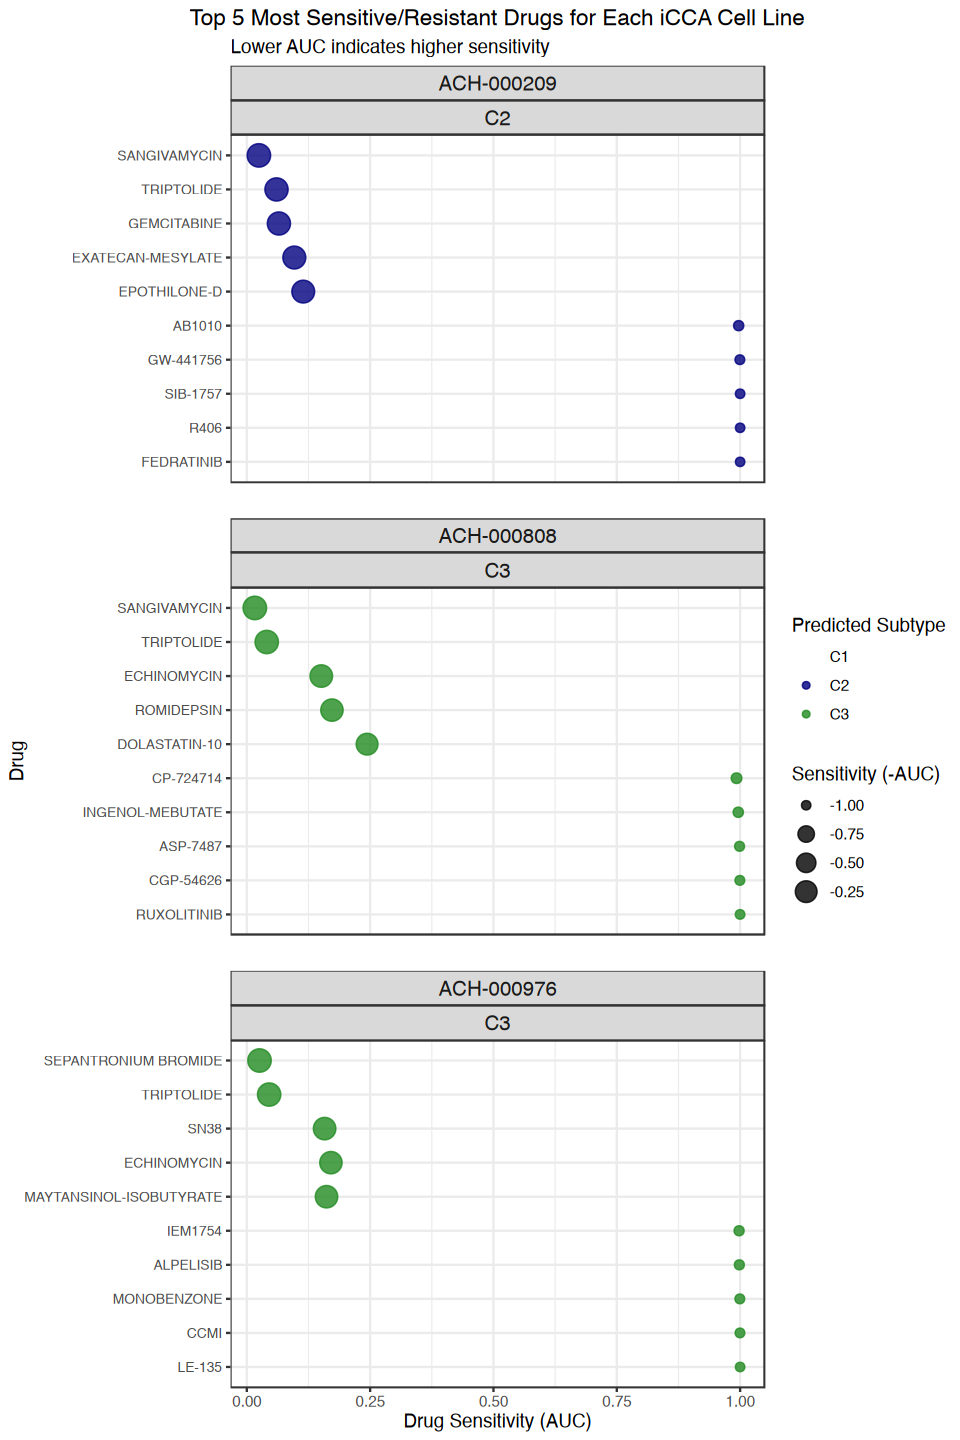

In [49]:
# --- 0. 环境准备：加载所需R包 ---
library(dplyr)
library(ggplot2)
library(forcats)

# --- 假设您的R环境中已经准备好了这个数据框 ---
# drug_data_with_subtypes: 
#   包含 DepMap_ID, Predicted_Subtype, Drug, AUC 等列

# --- 1. 为每个细胞系筛选Top药物 (精简和修正后) ---
cat("--- 步骤一：正在为每个细胞系筛选Top药物... ---\n")

# 定义要筛选的Top N数量
top_n <- 5

# 从您的数据中自动识别出有药敏结果的细胞系
cell_lines_with_drugs <- unique(drug_data_with_subtypes$DepMap_ID)

# 为每个细胞系筛选Top 5敏感和Top 5耐药的药物 (已移除冗余的left_join)
top_drugs_per_cell_line <- drug_data_with_subtypes %>%
  group_by(DepMap_ID) %>%
  
  # 找出最敏感的 (使用大写的 AUC)
  slice_min(order_by = AUC, n = top_n) %>%
  mutate(Status = "Most Sensitive") %>%
  
  bind_rows(
    drug_data_with_subtypes %>%
      filter(DepMap_ID %in% cell_lines_with_drugs) %>%
      group_by(DepMap_ID) %>%
      # 找出最耐药的 (使用大写的 AUC)
      slice_max(order_by = AUC, n = top_n) %>%
      mutate(Status = "Most Resistant")
  ) %>%
  ungroup()

# --- 2. 准备绘图 ---
cat("--- 步骤二：正在生成最终的可视化图表... ---\n")

# 使用正确的列名 Drug 和 AUC
plot_data <- top_drugs_per_cell_line %>%
  mutate(name_sorted = fct_reorder(Drug, -AUC))

options(repr.plot.width=8, repr.plot.height=12)
# --- 3. 绘制最终的点图 ---
ggplot(plot_data, aes(x = AUC, y = name_sorted)) +
  
  geom_point(aes(color = Predicted_Subtype, size = -AUC), alpha = 0.8) +
  
  facet_wrap(~ DepMap_ID + Predicted_Subtype, scales = "free_y", ncol = 1) +
  
  scale_color_manual(values = c(C1 = "firebrick3", C2 = "navy", C3 = "forestgreen"), drop = FALSE) +
  scale_size(range = c(2, 6)) +
  labs(
    title = "Top 5 Most Sensitive/Resistant Drugs for Each iCCA Cell Line",
    subtitle = "Lower AUC indicates higher sensitivity",
    x = "Drug Sensitivity (AUC)",
    y = "Drug",
    color = "Predicted Subtype",
    size = "Sensitivity (-AUC)"
  ) +
  theme_bw() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    strip.text = element_text(face = "bold", size = 12),
    axis.text.y = element_text(size = 8),
    panel.spacing = unit(1.5, "lines")
  )

## 构建并验证预后标志物（风险评分模型）

In [14]:
library(survival)
library(survminer)

In [21]:
df <- sample_info

# 1. 取时间（优先用天，否则用月*30补全）
df$time <- as.numeric(df$`Overall survival (days)`)
missing_time <- is.na(df$time) | df$time == 0
df$time[missing_time] <- as.numeric(df$`Overall survival (months)`[missing_time]) * 30

# 2. 生存状态（1=dead, 0=alive/other; 必须为0/1或TRUE/FALSE）
df$status <- as.numeric(df$`Vital state (1=Dead)`)
# 如果有其它编码（比如"Dead"/"Alive"），需要改成0/1

# 3. 去掉没有生存时间或没有状态的样本
df <- df[!is.na(df$time) & !is.na(df$status), ]

# （可选）行名设为样本名
rownames(df) <- df$SampleID

Warning message:
“Setting row names on a tibble is deprecated.”


### 单基因生存分析（KM和Cox）

In [ ]:
# 假设 pheno_rna 包含: Sample, time, status
expr_rna <- t(rna_zscore_major[genes_in_at_least_two, ])
pheno_rna <- df[, c("SampleID", "time", "status")]
dim(pheno_rna)
head(pheno_rna)

[1] 545   3

SampleID,time,status
<chr>,<dbl>,<dbl>
111,682,1
113,183,1
115,1806,0
117,808,1
121,1317,0
123,1101,1


In [97]:
# 1. 保证样本名顺序对应
common_samples <- intersect(rownames(expr_rna), pheno_rna$SampleID)
expr_rna_sub <- expr_rna[common_samples, , drop=FALSE]
pheno_rna_sub <- pheno_rna[match(common_samples, pheno_rna$SampleID), ]
stopifnot(all(rownames(expr_rna_sub) == pheno_rna_sub$SampleID))

# 2. 构造生存对象
surv_obj <- Surv(pheno_rna_sub$time, pheno_rna_sub$status)

# 3. 单基因分析
single_gene_results <- lapply(colnames(expr_rna_sub), function(gene) {
  expr <- expr_rna_sub[, gene]
  group <- ifelse(expr >= median(expr, na.rm=TRUE), "High", "Low")
  fit <- survfit(surv_obj ~ group)
  kmplot <- ggsurvplot(fit, data=data.frame(group=group, time=pheno_rna_sub$time, status=pheno_rna_sub$status), 
                       pval=TRUE, title=gene)
  cox <- coxph(surv_obj ~ expr)
  list(kmplot=kmplot, cox=summary(cox))
})

In [98]:
# 输出每个marker的cox回归结果
for(i in seq_along(top_marker_genes)){
  cat(paste0("Gene: ", top_marker_genes[i], "\n"))
  print(single_gene_results[[i]]$cox)
  cat("\n--------------------------\n")
}

Gene: PRSS22
Call:
coxph(formula = surv_obj ~ expr)

  n= 388, number of events= 180 

        coef exp(coef) se(coef)     z Pr(>|z|)
expr 0.02175   1.02199  0.05193 0.419    0.675

     exp(coef) exp(-coef) lower .95 upper .95
expr     1.022     0.9785    0.9231     1.131

Concordance= 0.542  (se = 0.025 )
Likelihood ratio test= 0.18  on 1 df,   p=0.7
Wald test            = 0.18  on 1 df,   p=0.7
Score (logrank) test = 0.18  on 1 df,   p=0.7


--------------------------
Gene: SOX4
Call:
coxph(formula = surv_obj ~ expr)

  n= 388, number of events= 180 

         coef exp(coef) se(coef)      z Pr(>|z|)
expr -0.08656   0.91708  0.08409 -1.029    0.303

     exp(coef) exp(-coef) lower .95 upper .95
expr    0.9171       1.09    0.7777     1.081

Concordance= 0.559  (se = 0.023 )
Likelihood ratio test= 1.04  on 1 df,   p=0.3
Wald test            = 1.06  on 1 df,   p=0.3
Score (logrank) test = 1.06  on 1 df,   p=0.3


--------------------------
Gene: SERPINE2
Call:
coxph(formula = surv_obj 

In [99]:
pdf("single_gene_KM_plots.pdf", width=6, height=5)
for(i in seq_along(top_marker_genes)){
  print(single_gene_results[[i]]$kmplot)
}
dev.off()

agg_record_1111544265 
                    2

In [100]:
cox_summary <- data.frame(
  Gene = character(),
  HR = numeric(),
  Lower95 = numeric(),
  Upper95 = numeric(),
  pvalue = numeric(),
  stringsAsFactors = FALSE
)

for(i in seq_along(top_marker_genes)){
  gene <- top_marker_genes[i]
  cox_res <- single_gene_results[[i]]$cox
  # 提取一元Cox模型结果
  HR <- exp(cox_res$coefficients[,"coef"])
  Lower95 <- exp(cox_res$conf.int[,"lower .95"])
  Upper95 <- exp(cox_res$conf.int[,"upper .95"])
  pvalue <- cox_res$coefficients[,"Pr(>|z|)"]
  cox_summary <- rbind(
    cox_summary,
    data.frame(Gene=gene, HR=HR, Lower95=Lower95, Upper95=Upper95, pvalue=pvalue)
  )
}

# 查看结果表
print(cox_summary)

       Gene        HR  Lower95  Upper95       pvalue
1    PRSS22 1.0219876 2.517063 3.100233 6.753285e-01
2      SOX4 0.9170793 2.176532 2.948783 3.032900e-01
3  SERPINE2 0.9559972 2.407718 2.829551 2.956435e-01
4    ARRDC2 0.8008123 2.068392 2.416684 7.202400e-06
5      SHC2 0.7702066 2.025187 2.317884 5.006305e-09
6   ONECUT1 0.8210188 2.164523 2.393900 2.878627e-10
7     HNF1B 0.7611512 2.028037 2.269071 3.939505e-13
8     WFDC2 1.1274332 2.896859 3.303779 5.455636e-05
9  SERPINB1 1.5467045 3.717096 6.184748 1.820990e-07
10     PLAU 1.4620857 3.755610 5.030338 8.511124e-14
11    HBEGF 1.4267985 3.550475 4.986070 4.409705e-09
12     CAPG 1.3940346 3.355568 4.979035 3.921255e-06
13     NBL1 1.2803632 3.183027 4.120032 1.469559e-06
14    EFHD2 1.6955657 4.274955 7.235027 2.134392e-11
15    ACSL5 1.3321525 3.326020 4.378353 4.825314e-08
16    NR1I2 1.1620285 2.843071 3.641171 5.608831e-03
17    ECHS1 1.0097282 2.383454 3.234431 8.997433e-01
18     SAA1 1.1006843 2.839819 3.192279 4.0086

In [56]:
write.csv(cox_summary, "single_gene_cox_results.csv", row.names=FALSE)

### 多基因RiskScore模型开发（训练集RNA-seq）

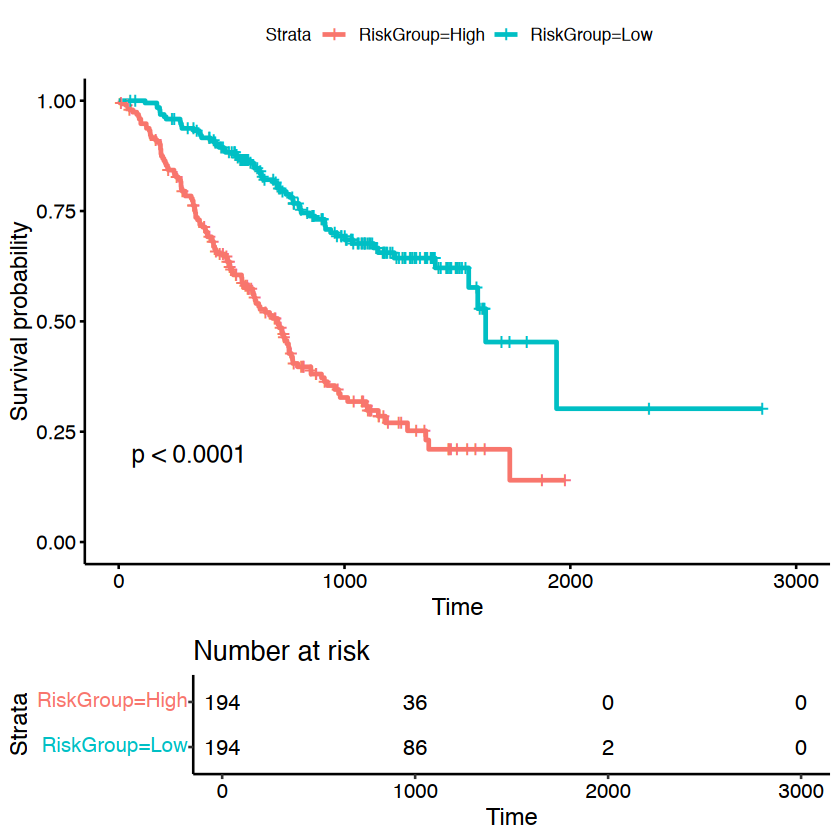

In [101]:
# 多基因COX
cox_formula <- as.formula(paste("Surv(time, status) ~", paste(top_marker_genes, collapse = "+")))
model_data <- cbind(pheno_rna_sub, expr_rna_sub)
cox_fit <- coxph(cox_formula, data = model_data)

# 风险评分
risk_score_rna <- predict(cox_fit, type = "risk")
pheno_rna_sub$RiskScore <- risk_score_rna

# 分组
pheno_rna_sub$RiskGroup <- ifelse(risk_score_rna >= median(risk_score_rna, na.rm=TRUE), "High", "Low")

# 训练集生存曲线
fit_rna <- survfit(Surv(time, status) ~ RiskGroup, data = pheno_rna_sub)
ggsurvplot(fit_rna, data = pheno_rna_sub, pval = TRUE, risk.table = TRUE)

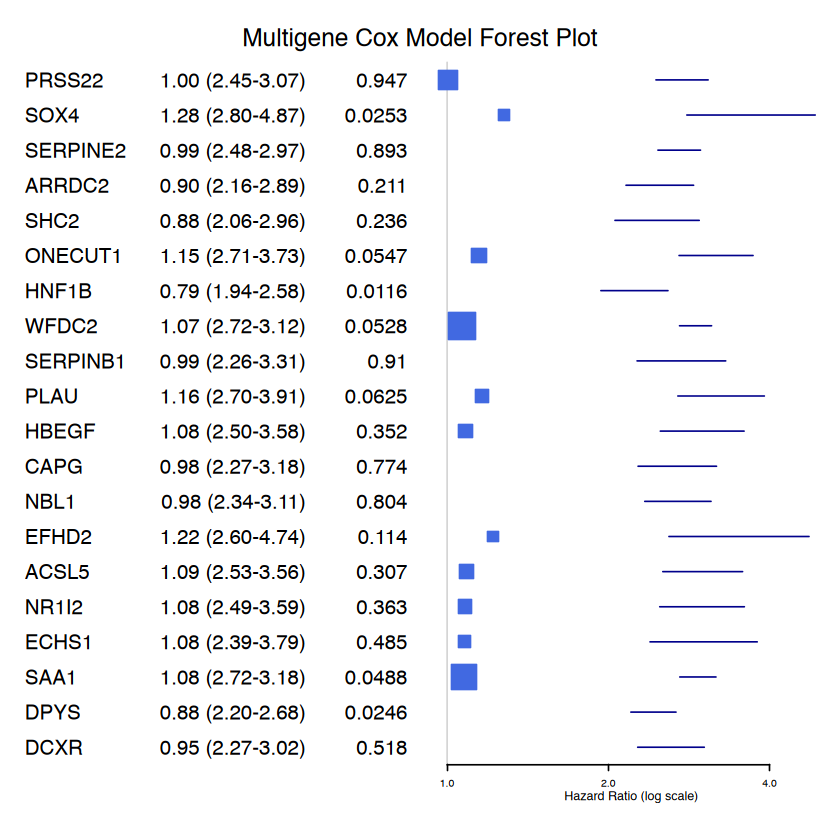

In [102]:
library(forestplot)
library(survival)
library(dplyr)

# 1. 提取多基因Cox结果
cox_sum <- summary(cox_fit)
gene_names <- rownames(cox_sum$coefficients)
HR <- exp(cox_sum$coefficients[,"coef"])
Lower95 <- exp(cox_sum$conf.int[,"lower .95"])
Upper95 <- exp(cox_sum$conf.int[,"upper .95"])
pval <- cox_sum$coefficients[,"Pr(>|z|)"]

# 2. 组合成数据框
forest_df <- data.frame(
  Gene = gene_names,
  HR = HR,
  Lower = Lower95,
  Upper = Upper95,
  pval = pval
)

# 3. 用 forestplot 包绘制
tabletext <- cbind(
  forest_df$Gene,
  sprintf("%.2f (%.2f-%.2f)", forest_df$HR, forest_df$Lower, forest_df$Upper),
  sprintf("%.3g", forest_df$pval)
)

forestplot(labeltext = tabletext,
           mean = forest_df$HR,
           lower = forest_df$Lower,
           upper = forest_df$Upper,
           zero = 1,
           xlog = TRUE,
           col = forestplot::fpColors(box = "royalblue", line = "darkblue", summary = "royalblue"),
           xlab = "Hazard Ratio (log scale)",
           title = "Multigene Cox Model Forest Plot")

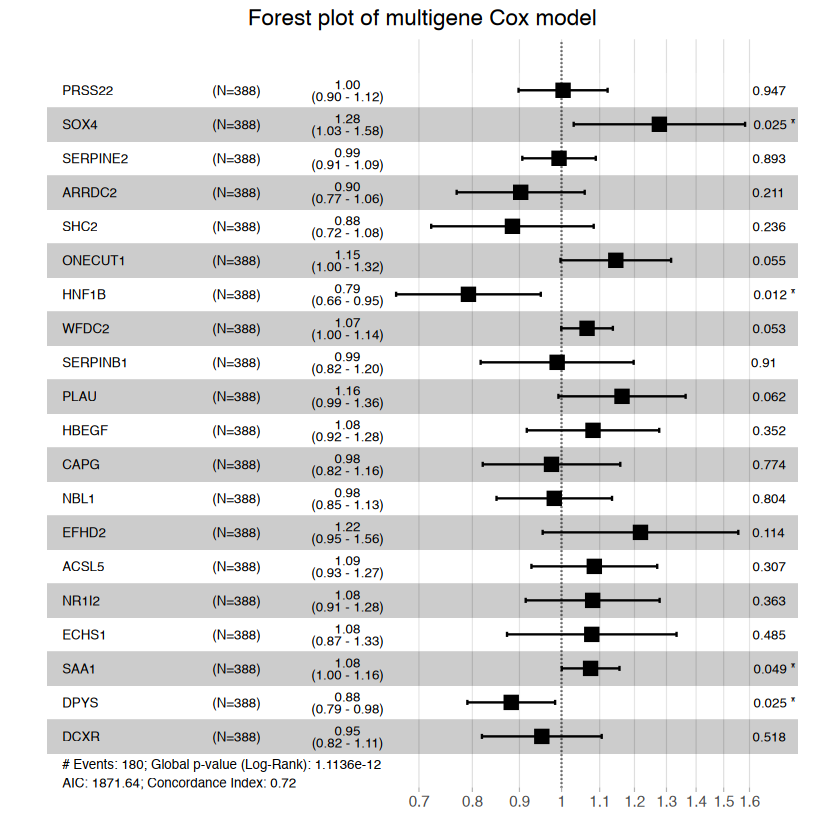

In [103]:
library(survminer)
ggforest(cox_fit, data = model_data, main = "Forest plot of multigene Cox model")

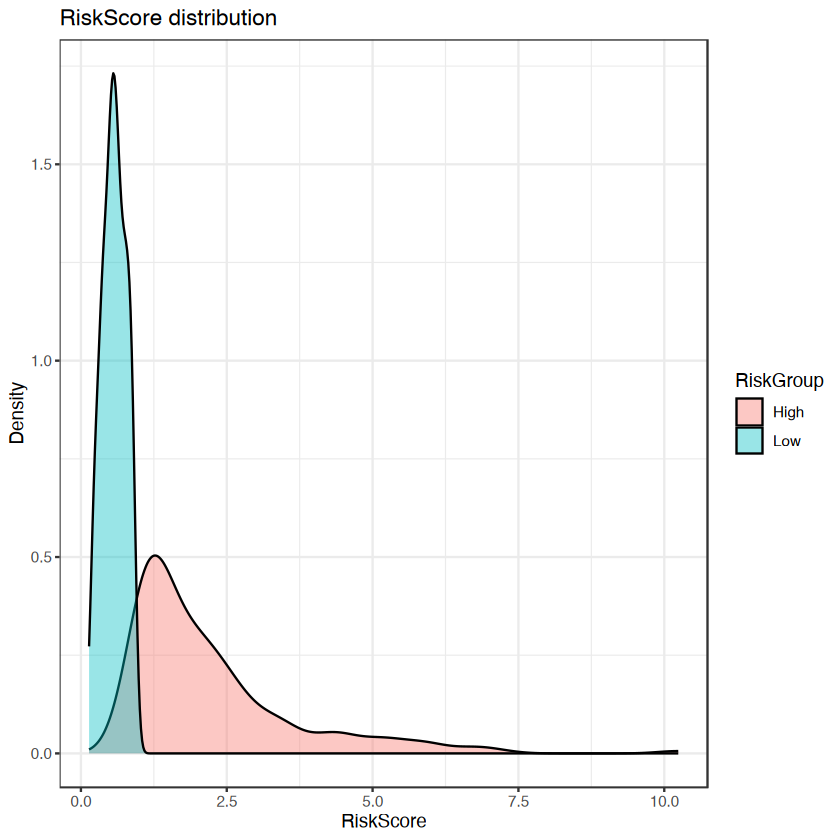

In [104]:
library(ggplot2)
ggplot(pheno_rna_sub, aes(x=RiskScore, fill=RiskGroup)) +
  geom_density(alpha=0.4) +
  labs(title="RiskScore distribution", x="RiskScore", y="Density") +
  theme_bw()

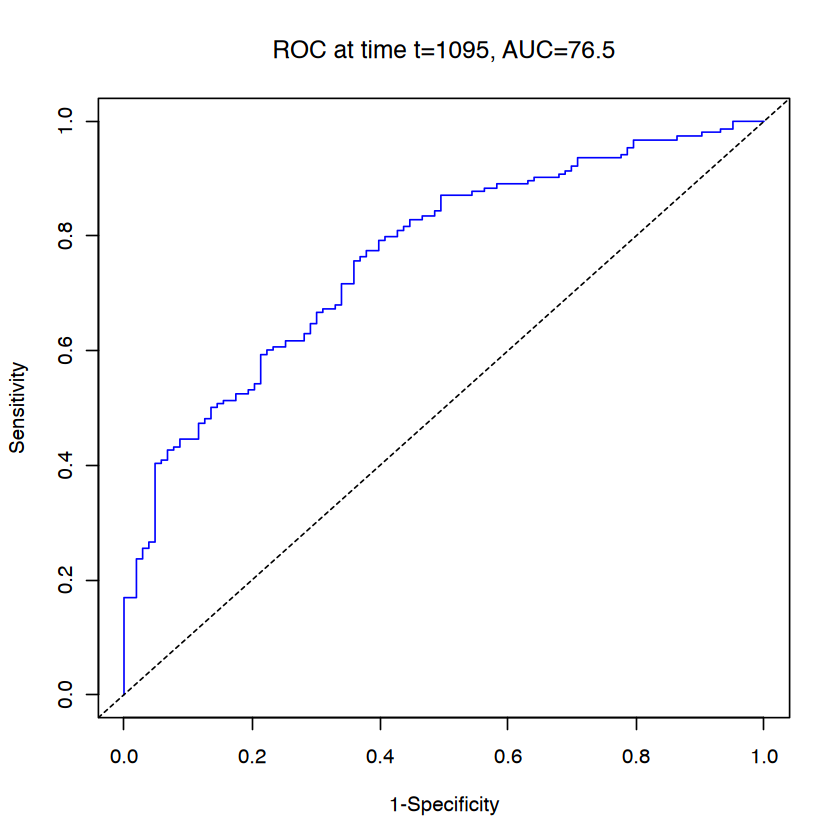

In [105]:
library(timeROC)
roc_obj <- timeROC(T=pheno_rna_sub$time, delta=pheno_rna_sub$status, marker=pheno_rna_sub$RiskScore, cause=1, times=c(365, 1095, 1825))
plot(roc_obj, time=1095, col="blue", add=FALSE)

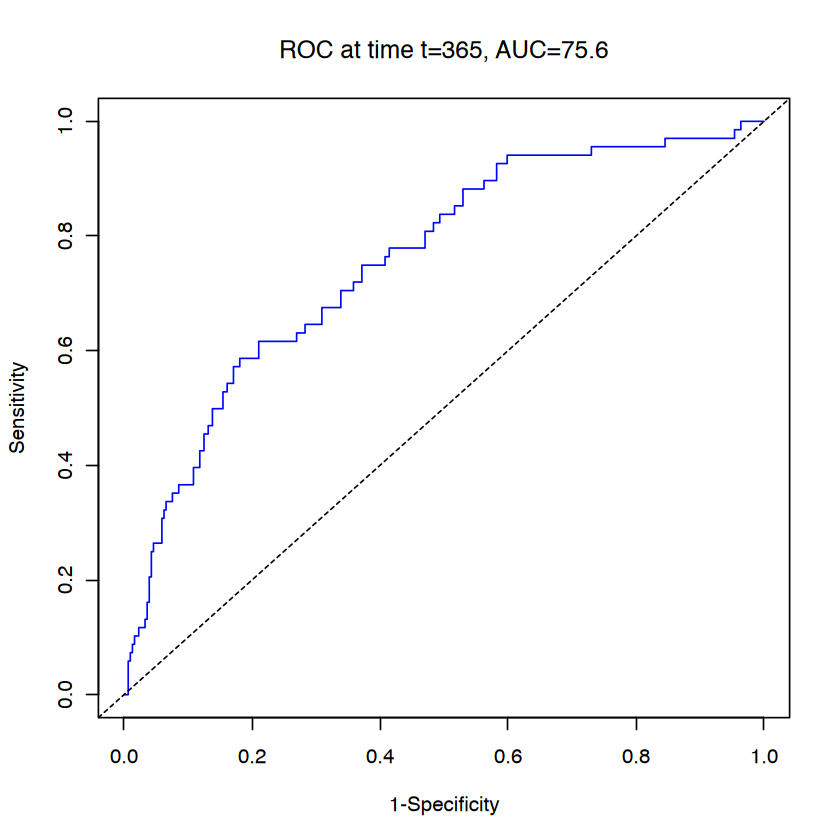

In [106]:
plot(roc_obj, time=365, col="blue", add=FALSE)

#### Lasso-Cox回归交叉验证自动筛选基因

<U+5165><U+9009><U+57FA><U+56E0><U+6570><U+FF1A> 12 
<U+5165><U+9009><U+57FA><U+56E0><U+FF1A> SOX4 ARRDC2 SHC2 HNF1B WFDC2 PLAU HBEGF EFHD2 ACSL5 SAA1 DPYS DCXR 


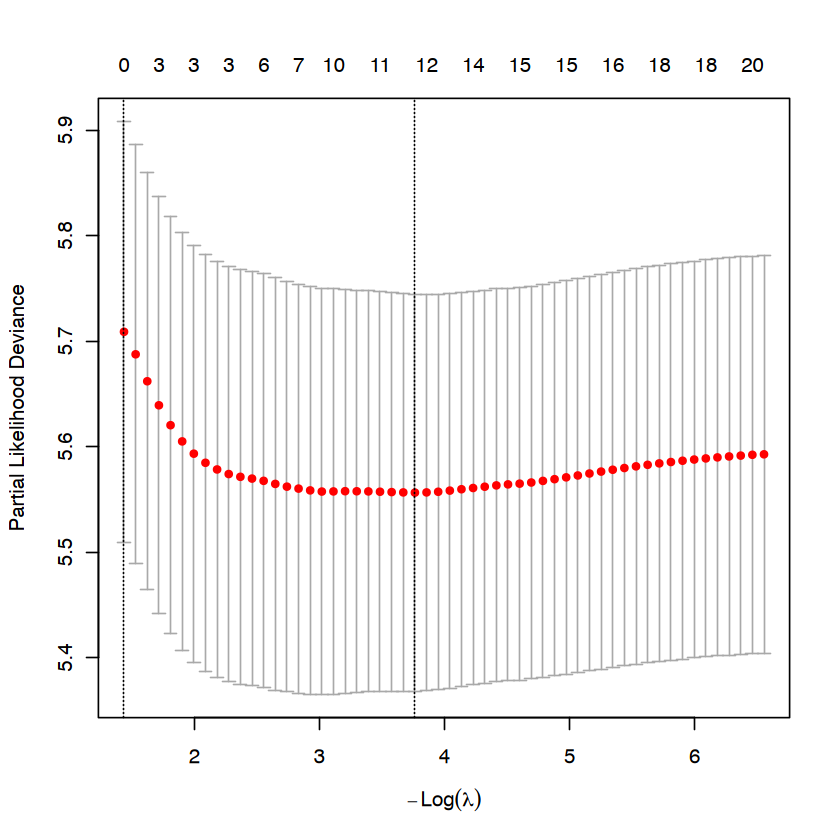

In [107]:
# 假设expr_rna_sub（样本x基因）和pheno_rna_sub（含time/status，顺序已对齐）
x <- as.matrix(expr_rna_sub)   # predictor matrix
y <- Surv(pheno_rna_sub$time, pheno_rna_sub$status)
# alpha=1为Lasso，family="cox"为Cox回归
set.seed(123)
cvfit <- cv.glmnet(x, y, family="cox", alpha=1, nfolds=10)
plot(cvfit)  # 可视化lambda选择过程

# 查看最佳lambda
lambda_min <- cvfit$lambda.min         # 最小均方误差点
lambda_1se <- cvfit$lambda.1se         # 更稀疏的1se点（更少基因）

# 查看入选基因和系数
coef_min <- coef(cvfit, s = lambda_min)
selected_genes <- rownames(coef_min)[as.numeric(coef_min) != 0]
cat("入选基因数：", length(selected_genes), "\n")
cat("入选基因：", selected_genes, "\n")

#### 用Lasso筛选出的基因重新建Cox模型和RiskScore

In [108]:
# 用筛选出的基因再做多因素Cox建模
x_lasso <- x[, selected_genes, drop=FALSE] # 精简版预测矩阵
lasso_cox_fit <- coxph(Surv(pheno_rna_sub$time, pheno_rna_sub$status) ~ ., data=as.data.frame(x_lasso))

# 计算RiskScore
risk_score_lasso <- predict(lasso_cox_fit, type="risk")
pheno_rna_sub$RiskScore_Lasso <- risk_score_lasso
pheno_rna_sub$RiskGroup_Lasso <- ifelse(risk_score_lasso >= median(risk_score_lasso, na.rm=TRUE), "High", "Low")

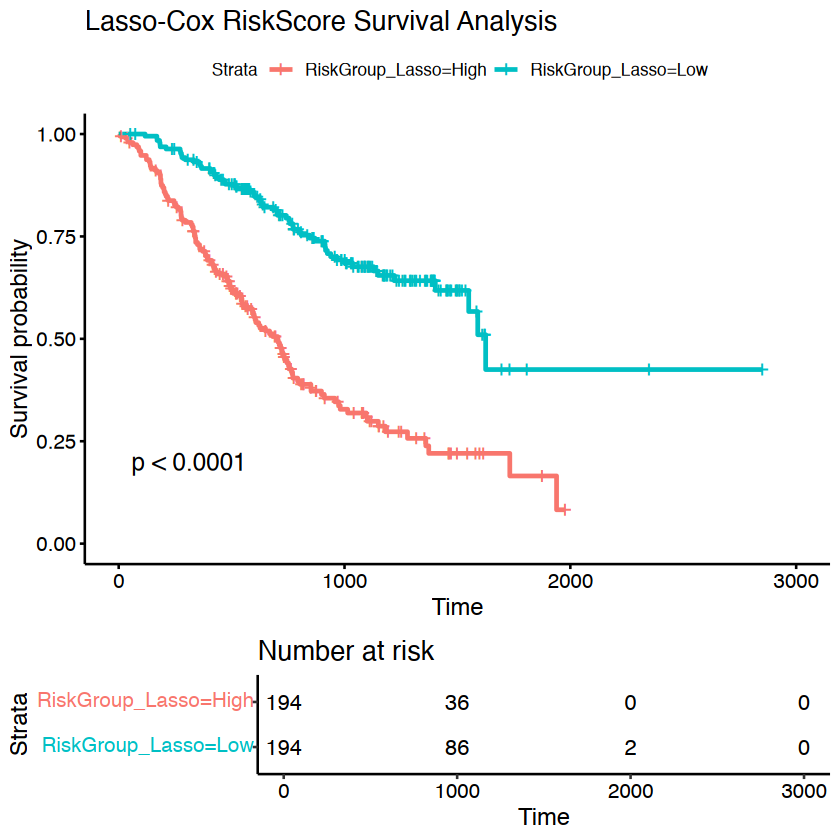

In [109]:
fit_lasso <- survfit(Surv(time, status) ~ RiskGroup_Lasso, data=pheno_rna_sub)
ggsurvplot(fit_lasso, data=pheno_rna_sub, pval=TRUE, risk.table=TRUE, title="Lasso-Cox RiskScore Survival Analysis")

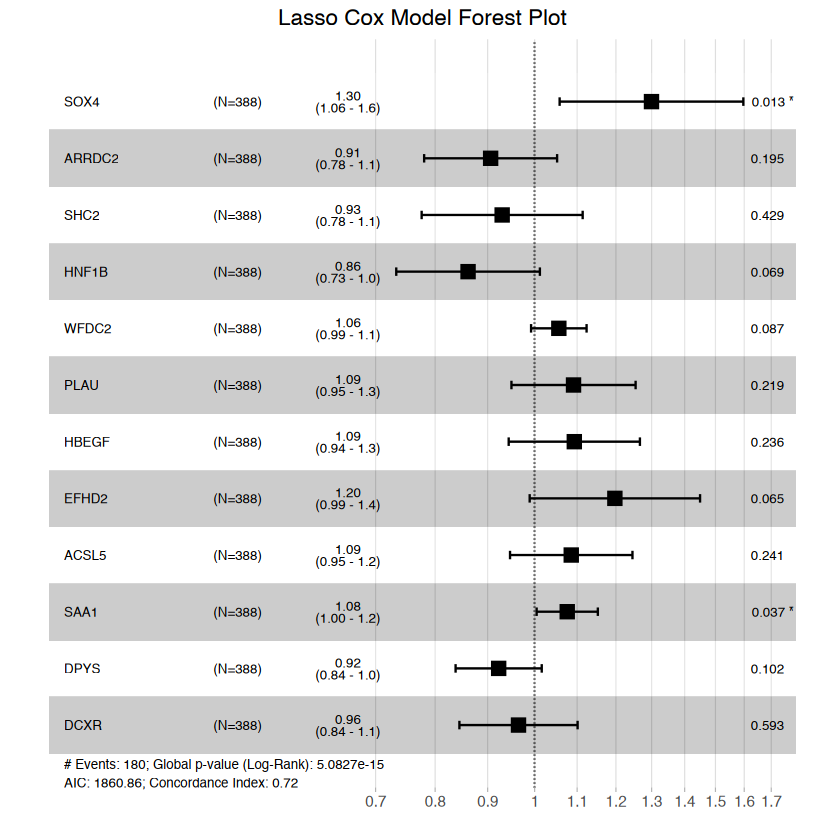

In [110]:
library(survminer)
ggforest(lasso_cox_fit, data=as.data.frame(x_lasso), main="Lasso Cox Model Forest Plot")

### 外部验证集（microarray）风险评分与生存分析

In [123]:
pheno_array <- df[, c("SampleID", "time", "status")]
dim(pheno_array)
head(pheno_array)

[1] 545   3

SampleID,time,status
<chr>,<dbl>,<dbl>
111,682,1
113,183,1
115,1806,0
117,808,1
121,1317,0
123,1101,1


In [124]:
# 查看哪些基因找不到
setdiff(top_marker_genes, rownames(corrected_array))

[1] "SHC2"  "HNF1B" "NBL1"  "SAA1"

In [125]:
# 统一处理小写和空格
rownames(corrected_array) <- trimws(toupper(rownames(corrected_array)))
top_marker_genes <- trimws(toupper(top_marker_genes))

In [126]:
valid_genes <- intersect(top_marker_genes, rownames(corrected_array))
# 警告未找到的基因
missing_genes <- setdiff(top_marker_genes, rownames(corrected_array))
if(length(missing_genes) > 0) warning("以下基因未在表达矩阵中找到：", paste(missing_genes, collapse=", "))

expr_array <- corrected_array[valid_genes, , drop=FALSE]
expr_array <- t(expr_array)

Warning message:
"<U+4EE5><U+4E0B><U+57FA><U+56E0><U+672A><U+5728><U+8868><U+8FBE><U+77E9><U+9635><U+4E2D><U+627E><U+5230><U+FF1A>SHC2, HNF1B, NBL1, SAA1"


In [127]:
# 保证样本名顺序对应
common_samples <- intersect(rownames(expr_array), pheno_array$SampleID)
expr_array_sub <- expr_array[common_samples, , drop=FALSE]
pheno_array_sub <- pheno_array[match(common_samples, pheno_array$SampleID), ]
stopifnot(all(rownames(expr_array_sub) == pheno_array_sub$SampleID))

In [116]:
surv_obj <- Surv(pheno_array_sub$time, pheno_array_sub$status)

# 3. 单基因分析
single_gene_results <- lapply(colnames(expr_array_sub), function(gene) {
  expr <- expr_array_sub[, gene]
  group <- ifelse(expr >= median(expr, na.rm=TRUE), "High", "Low")
  fit <- survfit(surv_obj ~ group)
  kmplot <- ggsurvplot(fit, data=data.frame(group=group, time=pheno_array_sub$time, status=pheno_array_sub$status), 
                       pval=TRUE, title=gene)
  cox <- coxph(surv_obj ~ expr)
  list(kmplot=kmplot, cox=summary(cox))
})

In [117]:
cox_summary <- data.frame(
  Gene = character(),
  HR = numeric(),
  Lower95 = numeric(),
  Upper95 = numeric(),
  pvalue = numeric(),
  stringsAsFactors = FALSE
)
genes = colnames(expr_array_sub)

for(i in seq_along(genes)){
  gene <- genes[i]
  cox_res <- single_gene_results[[i]]$cox
  # 提取一元Cox模型结果
  HR <- exp(cox_res$coefficients[,"coef"])
  Lower95 <- exp(cox_res$conf.int[,"lower .95"])
  Upper95 <- exp(cox_res$conf.int[,"upper .95"])
  pvalue <- cox_res$coefficients[,"Pr(>|z|)"]
  cox_summary <- rbind(
    cox_summary,
    data.frame(Gene=gene, HR=HR, Lower95=Lower95, Upper95=Upper95, pvalue=pvalue)
  )
}

# 查看结果表
print(cox_summary)

       Gene        HR  Lower95  Upper95       pvalue
1    PRSS22 1.0077485 2.117572 3.871292 0.9591060623
2      SOX4 1.0194613 2.048722 4.259179 0.9144500876
3  SERPINE2 1.0665970 2.508871 3.444498 0.3933222186
4    ARRDC2 0.8023435 1.826532 2.911349 0.1320441288
5   ONECUT1 0.7696802 1.960525 2.410830 0.0001274114
6     WFDC2 1.1678116 2.708729 3.929853 0.0553145480
7  SERPINB1 1.2185027 2.459413 5.206266 0.2012366927
8      PLAU 1.3768051 3.145483 5.228591 0.0006375635
9     HBEGF 1.4771780 3.099680 6.881281 0.0041523542
10     CAPG 1.5105562 2.732387 9.679708 0.0471663569
11    EFHD2 1.6882027 3.594084 9.279633 0.0002151963
12    ACSL5 1.2512802 2.950501 4.250677 0.0025097686
13    NR1I2 1.6188686 3.410258 8.467690 0.0006628095
14    ECHS1 0.8885487 1.873889 3.515435 0.5045219424
15     DPYS 1.0639890 2.466191 3.504792 0.4596783374
16     DCXR 1.0986191 2.334370 4.152622 0.4770177152


Warning message:
"<U+4EE5><U+4E0B><U+57FA><U+56E0><U+7F3A><U+5931><U+FF1A>SHC2, HNF1B, NBL1, SAA1"


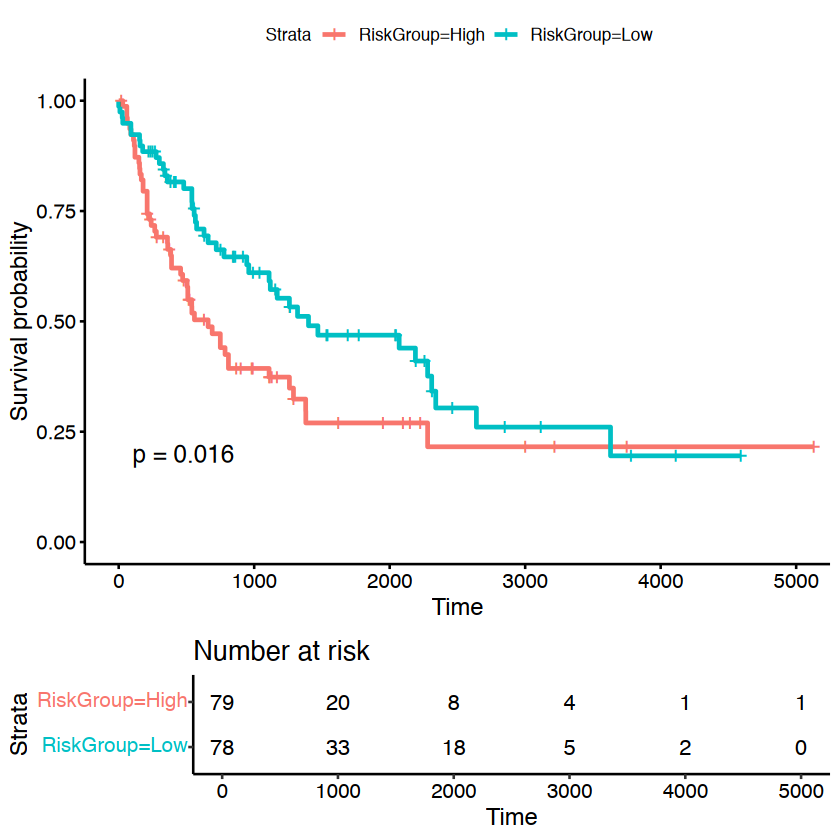

In [137]:
# 1. 先取出所有模型需要的基因（model_genes）
model_genes <- all.vars(formula(cox_fit))[-c(1,2)]   # Cox模型用到的基因

# 2. 生成表达矩阵（样本为行，基因为列）
corrected_array <- as.data.frame(corrected_array)
expr_array_sub <- corrected_array[model_genes, , drop=FALSE]
expr_array_sub <- t(expr_array_sub)
expr_array_sub <- as.data.frame(expr_array_sub)

# 3. 检查缺失基因，并补0（必须是列缺失！）
missing_genes <- setdiff(model_genes, colnames(expr_array_sub))
if(length(missing_genes)>0){
  warning("以下基因缺失：", paste(missing_genes, collapse=", "))
  for(g in missing_genes){
    expr_array_sub[[g]] <- 0  # 补0（或NA）
  }
}

# 4. 保证顺序和模型一致
expr_array_sub <- expr_array_sub[pheno_array_sub$SampleID, , drop=FALSE]
stopifnot(all(rownames(expr_array_sub) == pheno_array_sub$SampleID))

# 预测RiskScore
pheno_array_sub$RiskScore <- as.numeric(predict(cox_fit, newdata=expr_array_sub, type="risk"))
# 7. 分组
pheno_array_sub$RiskGroup <- ifelse(pheno_array_sub$RiskScore >= median(pheno_array_sub$RiskScore, na.rm=TRUE), "High", "Low")
# 8. 生存分析
fit_array <- survfit(Surv(time, status) ~ RiskGroup, data = pheno_array_sub)
ggsurvplot(fit_array, data = pheno_array_sub, pval = TRUE, risk.table = TRUE)


High  Low 
  79   78 

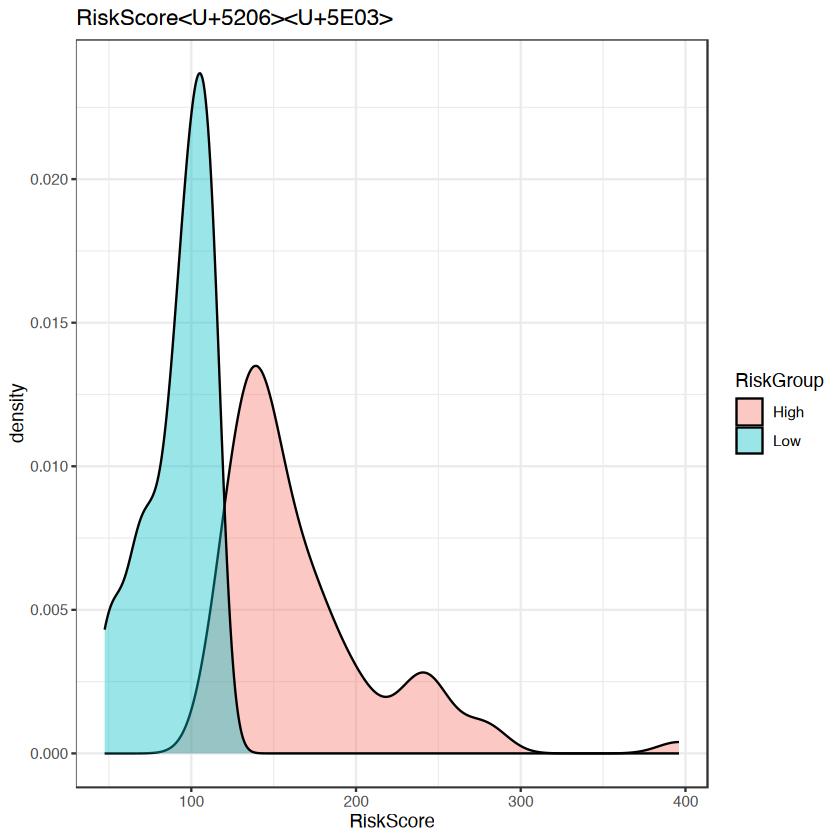

In [138]:
table(pheno_array_sub$RiskGroup)
ggplot(pheno_array_sub, aes(x=RiskScore, fill=RiskGroup)) + 
  geom_density(alpha=0.4) + theme_bw() + labs(title="RiskScore分布")

Warning message:
"<U+4EE5><U+4E0B><U+57FA><U+56E0><U+7F3A><U+5931><U+FF1A>status, SHC2, HNF1B, SAA1"


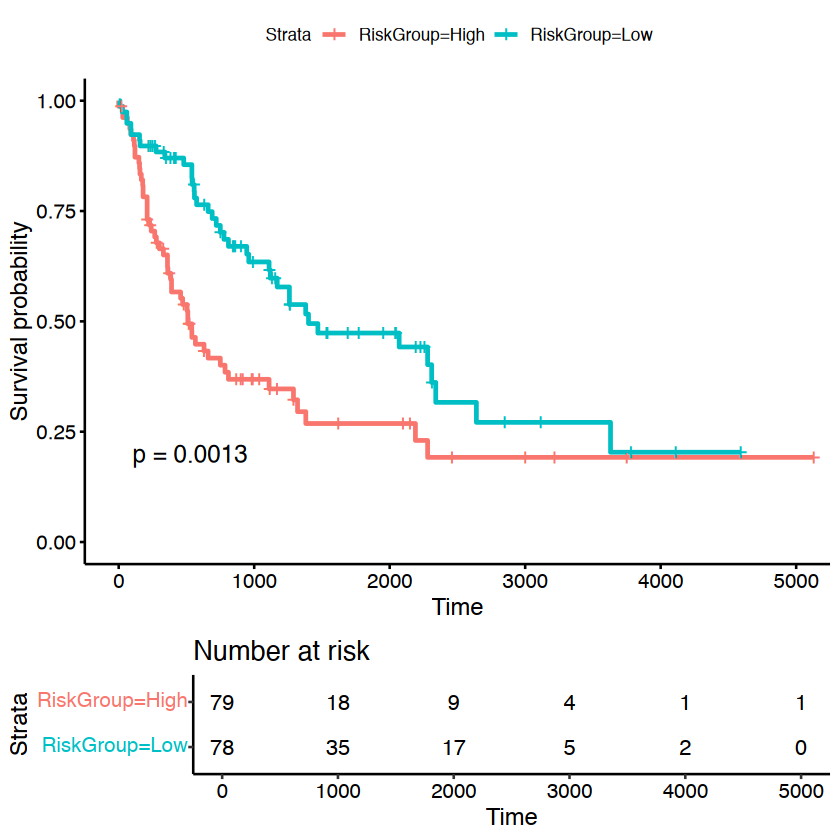

In [139]:
# 1. 先取出所有模型需要的基因（model_genes）
model_genes <- all.vars(formula(lasso_cox_fit))[-c(1,2)]   # Cox模型用到的基因

# 2. 生成表达矩阵（样本为行，基因为列）
corrected_array <- as.data.frame(corrected_array)
expr_array_sub <- corrected_array[model_genes, , drop=FALSE]
expr_array_sub <- t(expr_array_sub)
expr_array_sub <- as.data.frame(expr_array_sub)

# 3. 检查缺失基因，并补0（必须是列缺失！）
missing_genes <- setdiff(model_genes, colnames(expr_array_sub))
if(length(missing_genes)>0){
  warning("以下基因缺失：", paste(missing_genes, collapse=", "))
  for(g in missing_genes){
    expr_array_sub[[g]] <- 0  # 补0（或NA）
  }
}

# 4. 保证顺序和模型一致
expr_array_sub <- expr_array_sub[pheno_array_sub$SampleID, , drop=FALSE]
stopifnot(all(rownames(expr_array_sub) == pheno_array_sub$SampleID))

# 预测RiskScore
pheno_array_sub$RiskScore <- as.numeric(predict(lasso_cox_fit, newdata=expr_array_sub, type="risk"))
# 7. 分组
pheno_array_sub$RiskGroup <- ifelse(pheno_array_sub$RiskScore >= median(pheno_array_sub$RiskScore, na.rm=TRUE), "High", "Low")
# 8. 生存分析
fit_array <- survfit(Surv(time, status) ~ RiskGroup, data = pheno_array_sub)
ggsurvplot(fit_array, data = pheno_array_sub, pval = TRUE, risk.table = TRUE)


High  Low 
  79   78 

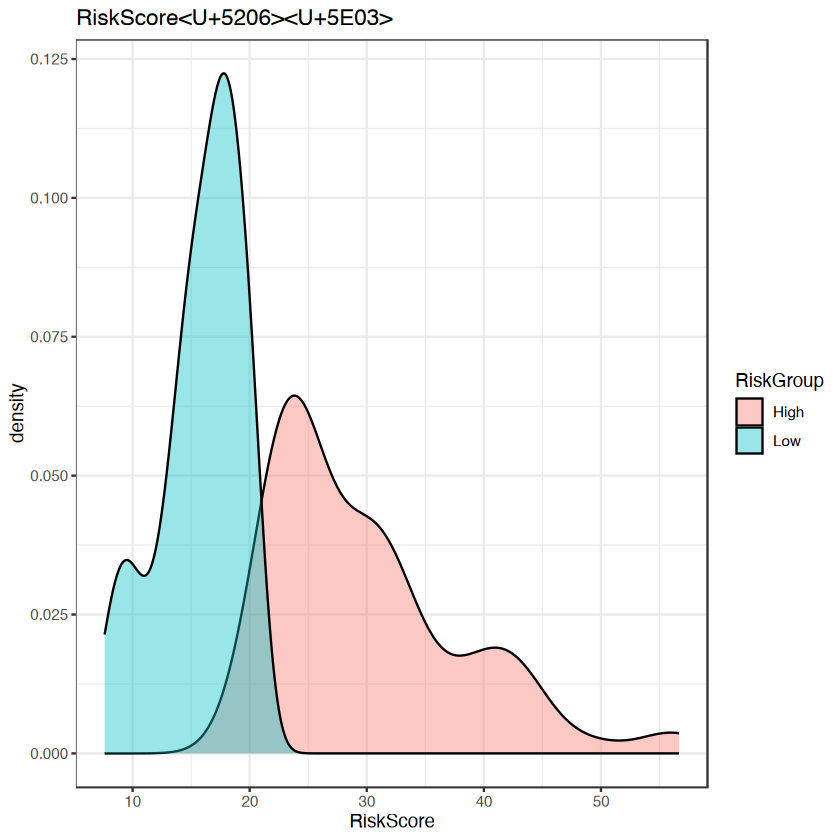

In [140]:
table(pheno_array_sub$RiskGroup)
ggplot(pheno_array_sub, aes(x=RiskScore, fill=RiskGroup)) + 
  geom_density(alpha=0.4) + theme_bw() + labs(title="RiskScore分布")

### 风险评分模型公式输出

In [191]:
beta <- coef(cox_fit)
cat("RiskScore = ", paste(sprintf("%.3f*%s", beta, names(beta)), collapse = " + "), "\n")

RiskScore =  -0.126*DPYS + 0.073*SAA1 + 0.136*ONECUT1 + -0.018*NBL1 + -0.233*HNF1B + 0.082*ACSL5 + 0.078*NR1I2 + 0.151*PLAU + -0.049*DCXR + 0.064*WFDC2 + -0.123*SHC2 + 0.004*PRSS22 + 0.197*EFHD2 + 0.079*HBEGF + -0.025*CAPG + -0.102*ARRDC2 + -0.011*SERPINB1 + 0.245*SOX4 + 0.076*ECHS1 + -0.006*SERPINE2 


In [197]:
beta <- coef(lasso_cox_fit)
cat("RiskScore = ", paste(sprintf("%.3f*%s", beta, names(beta)), collapse = " + "), "\n")

RiskScore =  -0.081*DPYS + 0.073*SAA1 + -0.149*HNF1B + 0.082*ACSL5 + 0.087*PLAU + -0.036*DCXR + 0.054*WFDC2 + -0.073*SHC2 + 0.180*EFHD2 + 0.089*HBEGF + -0.099*ARRDC2 + 0.262*SOX4 
